## Churn Analysis and Customer Intelligence — from Real Customer Reviews
**Company analysed: Spotify** | Data: ~2,000 public online customer reviews collected with a browser data-scraper extension.

**Important:** Public reviews have no billing or cancellation records, so this project measures a **churn signal** (an unhappy reviewer who talks about cancelling, refunds, being charged, or switching) — *not* the company's real churn rate.

**Sections 1-4** clean the reviews and analyse them (KPIs, charts, pivot tables, SQL). **Section 5** adds a churn model that predicts and explains the churn signal, estimates revenue at risk, suggests retention offers and shows the expected ROI. Section 5 uses clearly labelled assumptions for price and offer costs.

In [1]:
# import libraries
import re
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 1. Import data

In [2]:
# Settings - change these to analyse another company
# List ONE or MANY scraped csv files. The files can even have different column layouts
# (a scraper update adds/removes columns) - the cleaning step finds columns by their CONTENT.
RAW_FILES = ['Churn_analysis_Spotify_public.csv']      # e.g. ['spotify_part1.csv', 'spotify_part2.csv']
COMPANY   = 'Spotify'

# In Google Colab: upload the raw CSV file(s) if they are not already in the session
import os
missing = [f for f in RAW_FILES if not os.path.exists(f)]
if missing:
    try:
        from google.colab import files
        print("Select your scraped reviews CSV file(s)...")
        uploaded = files.upload()
        RAW_FILES = list(uploaded.keys())
    except ImportError:
        raise FileNotFoundError(f"Put {missing} in the same folder as this notebook")
print("Using files:", RAW_FILES)

Using files: ['Churn_analysis_Spotify_public.csv']


In [3]:
raw_list = [pd.read_csv(f) for f in RAW_FILES]
for f, r in zip(RAW_FILES, raw_list):
    print(f, '->', r.shape)

Churn_analysis_Spotify_public.csv -> (2000, 9)


In [4]:
# the scraper gave random CSS-class names as column names (and their order can change between scrapes)
for i, c in enumerate(raw_list[0].columns):
    print(i, '|', c)

0 | country
1 | reviewer_review_count
2 | review_date
3 | stars
4 | review_link
5 | title
6 | text
7 | experience_date
8 | review_type


## 2. Data cleaning

In [5]:
# a. rename col - scraper css names to meaningful names (found by looking at the content of each column)
# b. drop columns - reviewer name, profile link, avatar, initials (personal data, not needed)
# c. extract numeric rating from the star image url
# d. change data type - review_date, experience_date
# e. fix missing values - review text
# f. check duplicates

#### a. Rename cols & b. Drop columns

In [6]:
def find_col(raw, pattern, exclude=(), min_share=0.3):
    """Find the column whose values match a regex most often.
    The scraper's column names are random css names and their order can change,
    so we look at the content of each column instead."""
    best, best_share = None, 0
    for c in raw.columns:
        if c in exclude:
            continue
        share = raw[c].astype(str).str.contains(pattern, regex=True, na=False).mean()
        if share > best_share:
            best, best_share = c, share
    if best_share < min_share:
        raise ValueError(f"Could not find a column that looks like {pattern!r}")
    return best


def standardize(raw):
    c_stars   = find_col(raw, r'stars-\d\.svg')                                   # star image url
    c_url     = find_col(raw, r'/reviews/[0-9a-f]{20,}')                        # link of the review (we keep only its id)
    c_count   = find_col(raw, r'^\d+ reviews?$')                                  # "18 reviews"
    c_country = find_col(raw, r'^[A-Z]{2}$')                                      # "GB"
    cols = list(raw.columns)
    i = cols.index(c_url)
    # date formats seen: "Jul 3, 2026", "Updated Jul 3, 2026", "November 17, 2026", "2 days ago"
    # and "9-Sep-25" (what Excel turns dates into if you open + save the csv)
    date_pat = r'^(?:Updated )?[A-Z][a-z]{2,8} \d{1,2}, \d{4}$|^\d{1,2}-[A-Z][a-z]{2}-\d{2,4}$|\bago$'
    c_rdate   = find_col(raw, date_pat, exclude=cols[i:])               # review date sits BEFORE the review link
    c_edate   = find_col(raw, date_pat, exclude=cols[:i + 1])           # date of experience sits AFTER the review text
    c_type    = find_col(raw, r'review$', exclude=[c_count])                      # "Unprompted review"
    i = list(raw.columns).index(c_url)                                            # title and text sit right after the link
    c_title, c_text = raw.columns[i + 1], raw.columns[i + 2]

    # we only take the columns we need -> reviewer name / profile link / avatar (personal data) are dropped
    return pd.DataFrame({
        'review_id': raw[c_url].astype(str).str.extract(r'/reviews/([0-9a-f]+)')[0], 'country': raw[c_country], 'reviewer_review_count': raw[c_count],
        'review_date': raw[c_rdate], 'stars_url': raw[c_stars], 'title': raw[c_title],
        'text': raw[c_text], 'experience_date': raw[c_edate], 'review_type': raw[c_type]})


frames = []
for f, raw in zip(RAW_FILES, raw_list):
    part = standardize(raw)
    part['source_file'] = f
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   review_id              2000 non-null   str  
 1   country                2000 non-null   str  
 2   reviewer_review_count  1998 non-null   str  
 3   review_date            2000 non-null   str  
 4   stars_url              2000 non-null   str  
 5   title                  2000 non-null   str  
 6   text                   1937 non-null   str  
 7   experience_date        2000 non-null   str  
 8   review_type            1997 non-null   str  
 9   source_file            2000 non-null   str  
dtypes: str(10)
memory usage: 156.4 KB


#### c. Rating from star image url

In [7]:
# ".../stars-1.svg" -> 1
df['rating'] = df['stars_url'].str.extract(r'stars-(\d)')[0].astype(int)
df.drop(columns=['stars_url'], inplace=True)
df['rating'].value_counts().sort_index()

rating
1    1416
2     198
3     101
4      72
5     213
Name: count, dtype: int64

#### d. Change data type

In [8]:
# review_date has some values like "Updated Jul 3, 2026" (the review was edited)
# and a few very recent reviews only show "2 days ago" - that can't be parsed as a date
df['was_updated'] = df['review_date'].astype(str).str.startswith('Updated')

def parse_dates(s):
    s = s.astype(str).str.replace('Updated ', '', regex=False).str.strip()
    out = pd.to_datetime(s, format='%d-%b-%y', errors='coerce')               # Excel style: 9-Sep-25
    rest = out.isna()
    out[rest] = pd.to_datetime(s[rest], errors='coerce', format='mixed')      # Jul 3, 2026 / November 17, 2026
    return out

df['review_date'] = parse_dates(df['review_date'])
df['experience_date'] = parse_dates(df['experience_date'])

print('reviews with a relative date ("2 days ago"):', df['review_date'].isna().sum())
# for those few reviews use the date of experience as review date
df['review_date'] = df['review_date'].fillna(df['experience_date'])

# "18 reviews" -> 18
df['reviewer_review_count'] = df['reviewer_review_count'].astype(str).str.extract(r'(\d+)')[0].astype(float)

df[['review_date', 'experience_date']].isna().sum()

reviews with a relative date ("2 days ago"): 9


review_date        0
experience_date    0
dtype: int64

#### e. Fix missing values

In [9]:
print('missing title :', df['title'].isna().sum())
print('missing text  :', df['text'].isna().sum())   # some people only wrote a title

df['title'] = df['title'].fillna('')
df['text']  = df['text'].fillna('')

# one text col to search for keywords
df['full_text'] = (df['title'] + '. ' + df['text']).str.strip().str.lower()
df['text_length'] = df['text'].str.len()

missing title : 0
missing text  : 63


#### f. Duplicates

In [10]:
print('duplicate reviews:', df['review_id'].duplicated().sum())
df = df.drop_duplicates('review_id').reset_index(drop=True)
df['company'] = COMPANY
df.shape

duplicate reviews: 0


(2000, 14)

## 3. Feature Engineering & Data Analysis

#### Create new cols - churn flag (churn signal)

In [11]:
# Without a cancellation_date col we build a churn signal from the review itself:
# 1) low_rating     - 1 or 2 stars
# 2) churn_keyword  - review talks about cancelling / refund / being charged / switching / leaving
# 3) churn_signal   - BOTH (unhappy AND talking about leaving)

df['low_rating'] = np.where(df['rating'] <= 2, 1, 0)

churn_words = [
    r"cancel", r"unsubscrib", r"refund", r"charged", r"charging", r"still (?:charge|bill|tak)",
    r"delete[d]? (?:my )?account", r"close[d]? (?:my )?account", r"switch(?:ed|ing)? to",
    r"moved to", r"left spotify", r"leaving", r"uninstall", r"no longer", r"never again",
    r"apple music", r"youtube music", r"tidal", r"deezer", r"amazon music",
]
churn_pattern = "|".join(churn_words)

df['churn_keyword_hits'] = df['full_text'].str.count(churn_pattern)
df['churn_keyword'] = np.where(df['churn_keyword_hits'] > 0, 1, 0)
df['churn_signal'] = np.where((df['low_rating'] == 1) & (df['churn_keyword'] == 1), 1, 0)

df[['rating', 'low_rating', 'churn_keyword', 'churn_signal']].mean().round(3)

rating           1.734
low_rating       0.807
churn_keyword    0.282
churn_signal     0.263
dtype: float64

In [12]:
# complaint themes (1 = review mentions the theme)
themes = {
    "billing":   r"charg|bill|refund|payment|fee|renew|subscription|price|expensive|cost",
    "ads":       r"\bads?\b|advert|commercial",
    "support":   r"customer service|support|contact|no response|reply|replied|chat",
    "cancel":    r"cancel|unsubscrib|delete (?:my )?account",
    "app_bug":   r"bug|glitch|crash|freez|not working|doesn.?t work|won.?t (?:play|load)|loading",
    "account":   r"account|login|log in|password|banned|suspend|hacked",
    "algorithm": r"algorithm|shuffle|recommend|playlist|queue",
}
for name, pat in themes.items():
    df['theme_' + name] = df['full_text'].str.contains(pat, regex=True).astype(int)

theme_cols = [c for c in df.columns if c.startswith('theme_')]
df['complaint_themes'] = df[theme_cols].sum(axis=1)   # how many different themes in one review
df[theme_cols].mean().mul(100).round(1).sort_values(ascending=False)

theme_billing      34.7
theme_support      27.6
theme_algorithm    18.6
theme_account      18.6
theme_ads          17.6
theme_cancel       14.0
theme_app_bug       5.8
dtype: float64

In [13]:
# time cols
df['review_month'] = df['review_date'].dt.to_period('M')
df['review_year']  = df['review_date'].dt.year
df['days_to_review'] = (df['review_date'] - df['experience_date']).dt.days   # delay between experience and review
df.head()

,review_id,country,reviewer_review_count,review_date,title,text,experience_date,review_type,source_file,rating,...,theme_ads,theme_support,theme_cancel,theme_app_bug,theme_account,theme_algorithm,complaint_themes,review_month,review_year,days_to_review
0,6afbf8ba1e72334f49207818,NZ,1.0,2026-11-17,What's with the forced/mandatory Shuffle featu...,Are you kidding me?!The mandatory shuffle on S...,2026-11-17,Unprompted review,Churn_analysis_Spotify_public.csv,1,...,0,0,0,0,0,1,2,2026-11,2026,0
1,6afaf894e120c2da1da4ae74,GB,27.0,2026-11-16,Double billing and an exhausting battle for a ...,"Two £12.99 Spotify payments, only three days a...",2026-11-16,Unprompted review,Churn_analysis_Spotify_public.csv,1,...,0,0,0,0,1,1,3,2026-11,2026,0
2,6afa1917e53cb49355486814,US,6.0,2026-11-14,TitleTitle: Charged $69 for a Spotify Account ...,"**Title: Spotify Charged Me for Months, Then R...",2026-11-14,Unprompted review,Churn_analysis_Spotify_public.csv,1,...,0,1,1,0,1,0,4,2026-11,2026,0
3,6af940d07f1d7b3c8baab0d3,AU,1.0,2026-11-15,Almost 10 years since I’ve used this…,Almost 10 years since I’ve used this app and e...,2026-11-15,Unprompted review,Churn_analysis_Spotify_public.csv,1,...,0,0,0,0,0,1,1,2026-11,2026,0
4,6af797a18ebefaa03a550986,GB,3.0,2026-11-13,Impossible to cancel premium,Impossible to cancel premium and then proceed ...,2026-11-13,Unprompted review,Churn_analysis_Spotify_public.csv,1,...,0,0,1,0,0,0,2,2026-11,2026,0


## Data Analysis (KPIs)

In [14]:
# 1. Churn Signal Rate
churn_rate = df['churn_signal'].mean() * 100
print("Churn Signal Rate = ", round(churn_rate, 2), "%")

Churn Signal Rate =  26.3 %


In [15]:
# 2. Non-churn share (retention-side)
retention_rate = 100 - churn_rate
print("Non-churn Share = ", round(retention_rate, 2), "%")

Non-churn Share =  73.7 %


In [16]:
# 3. Churn language by rating
# churn_signal is 0 for 3-5 stars by definition (it needs a low rating), so also show churn_keyword:
# the share of reviews that talk about cancelling / refunds / switching, whatever the rating
churn_by_rating = (df.groupby('rating')
                     .agg(reviews=('review_id', 'count'),
                          churn_keyword_pct=('churn_keyword', lambda s: round(s.mean() * 100, 2)),
                          churn_signal_pct=('churn_signal', lambda s: round(s.mean() * 100, 2)))
                     .reset_index())
print(churn_by_rating)

   rating  reviews  churn_keyword_pct  churn_signal_pct
0       1     1416              33.55             33.55
1       2      198              25.76             25.76
2       3      101              11.88              0.00
3       4       72               6.94              0.00
4       5      213               9.86              0.00


In [17]:
# 4. Churn signal by country (only countries with 15+ reviews) + review count
by_country = (df.groupby('country')
                .agg(reviews=('review_id', 'count'),
                     churn_signal_pct=('churn_signal', lambda s: round(s.mean() * 100, 2)),
                     avg_rating=('rating', lambda s: round(s.mean(), 2)))
                .query('reviews >= 15')
                .sort_values('churn_signal_pct', ascending=False))
by_country

,reviews,churn_signal_pct,avg_rating
country,,,
CA,83,38.55,1.31
AE,15,33.33,1.33
GB,744,33.33,1.54
PT,17,29.41,1.71
AU,58,27.59,1.81
IE,41,24.39,1.73
US,440,24.32,1.90
IT,31,22.58,1.87
ZA,20,20.00,2.00


In [18]:
# 5. Average rating
avg_rating = df['rating'].mean()
print("Average Rating = ", round(avg_rating, 2), "out of 5")

Average Rating =  1.73 out of 5


In [19]:
# 6. Avg days between experience and review
print("Avg days from experience to review = ", round(df['days_to_review'].mean(), 1))
print("Median = ", df['days_to_review'].median())

Avg days from experience to review =  8.8
Median =  1.0


In [20]:
# 7. Billing complaints among churn-signal reviews - (our "revenue at risk" idea: money problems drive exits)
billing_churn_share = df.loc[df['churn_signal'] == 1, 'theme_billing'].mean() * 100
print("Billing mentioned in churn-signal reviews = ", round(billing_churn_share, 1), "%")

Billing mentioned in churn-signal reviews =  68.8 %


In [21]:
# 8. Support complaint rate
support_rate = df['theme_support'].mean() * 100
print("Support issue rate = ", round(support_rate, 2), "%")

Support issue rate =  27.55 %


In [22]:
# 9. Avg complaint themes per review
print("Avg themes per review = ", round(df['complaint_themes'].mean(), 2))

Avg themes per review =  1.37


In [23]:
# 10. Correlation: support complaint vs churn signal
corr = df['theme_support'].corr(df['churn_signal'])
print("Correlation between support complaint vs churn signal is = ", round(corr, 2))

Correlation between support complaint vs churn signal is =  0.21


In [24]:
# 11. Create a column using existing cols - churn_score (0-100) and churn_risk
# score = unhappiness (rating) + how many churn words + billing/cancel complaint
rating_part = (5 - df['rating']) / 4 * 50                       # 0 - 50
kw_part     = df['churn_keyword_hits'].clip(upper=3) / 3 * 30   # 0 - 30
theme_part  = np.where((df['theme_billing'] == 1) | (df['theme_cancel'] == 1), 20, 0)  # 0 or 20

df['churn_score'] = (rating_part + kw_part + theme_part).round(0)

conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] >= 70)
]
choices = ['low', 'med', 'high']
df['churn_risk'] = np.select(conditions, choices, default='unknown')

df['churn_risk'].value_counts()

churn_risk
med     891
high    622
low     487
Name: count, dtype: int64

#### Export dataframe

In [25]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)
print("saved: exported_churn_data.csv", df.shape)

saved: exported_churn_data.csv (2000, 31)


## 4. Visualization using Matplotlib

In [26]:
# best practice to create a copy then work on it
df_visual = df.copy()

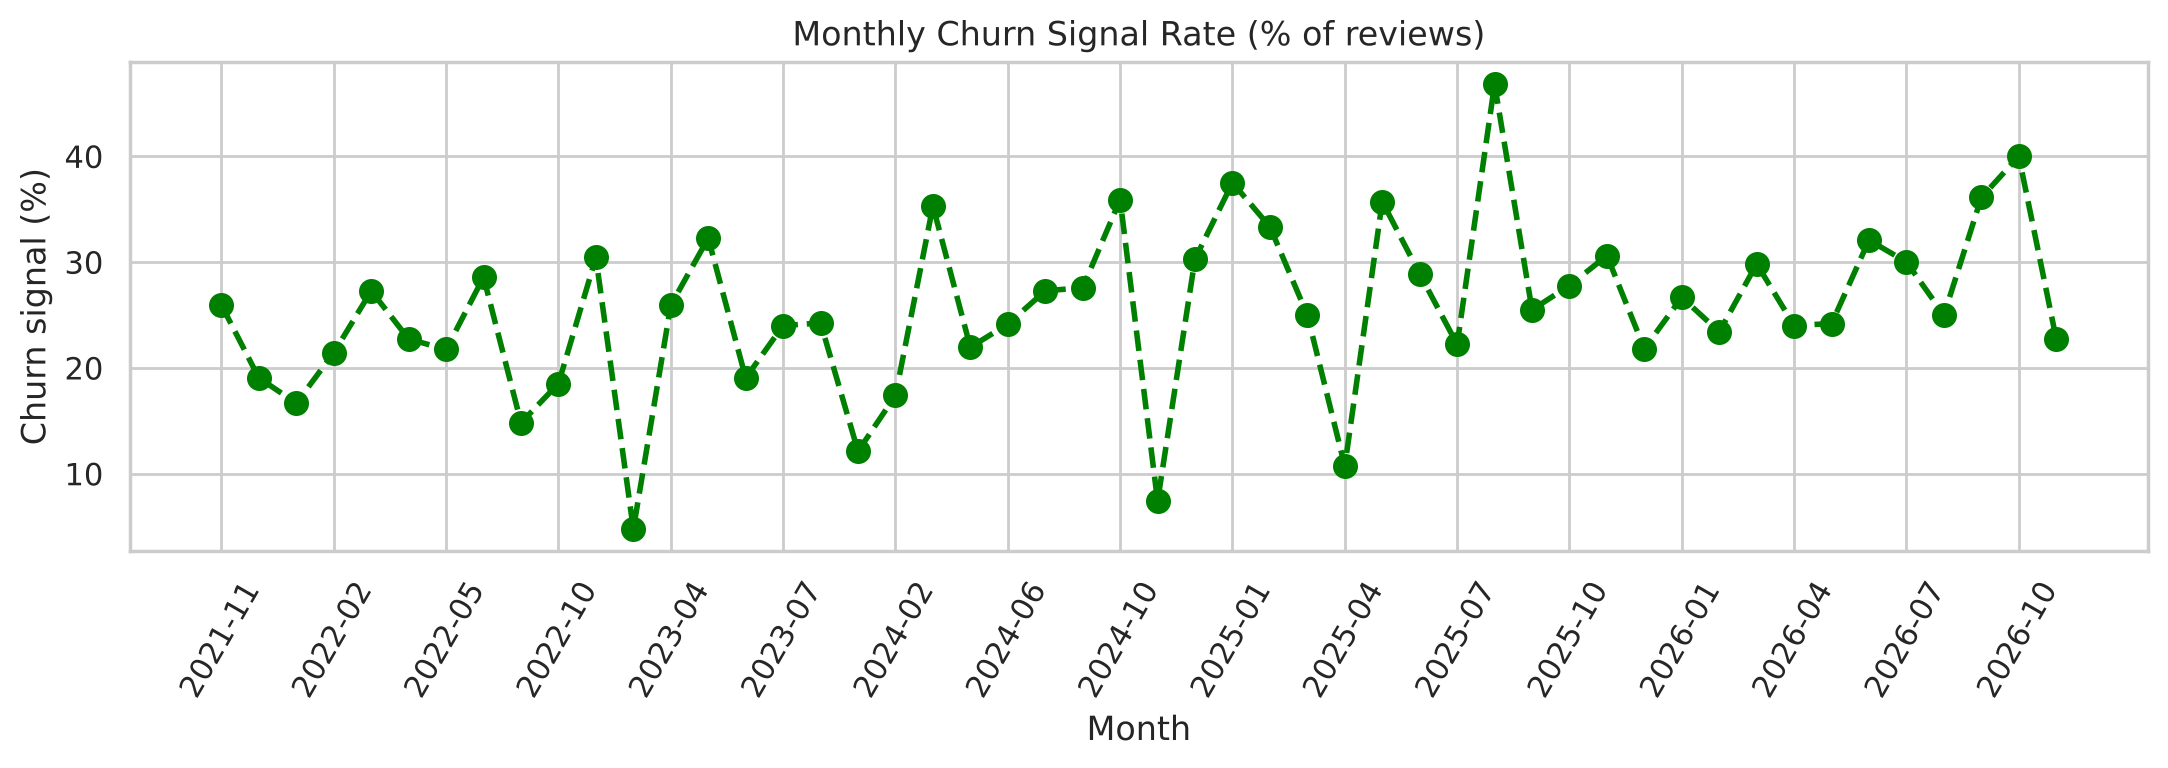

In [27]:
# 4.1 Monthly Churn Signal Trend (Time Series KPI)
# keep only months with 20+ reviews (first and last month are incomplete)
monthly = (df_visual.groupby('review_month')
                    .agg(reviews=('review_id', 'count'), churn_rate=('churn_signal', 'mean')))
monthly = monthly[monthly['reviews'] >= 20]

plt.figure(figsize=(11, 4))
plt.plot(monthly.index.astype(str), monthly['churn_rate'] * 100, color='green', marker='o',
         linestyle='dashed', linewidth=2, markersize=8)
plt.title('Monthly Churn Signal Rate (% of reviews)')
plt.xlabel('Month')
plt.ylabel('Churn signal (%)')
plt.xticks(range(0, len(monthly), 3), monthly.index.astype(str)[::3], rotation=60)
plt.tight_layout()
plt.show()

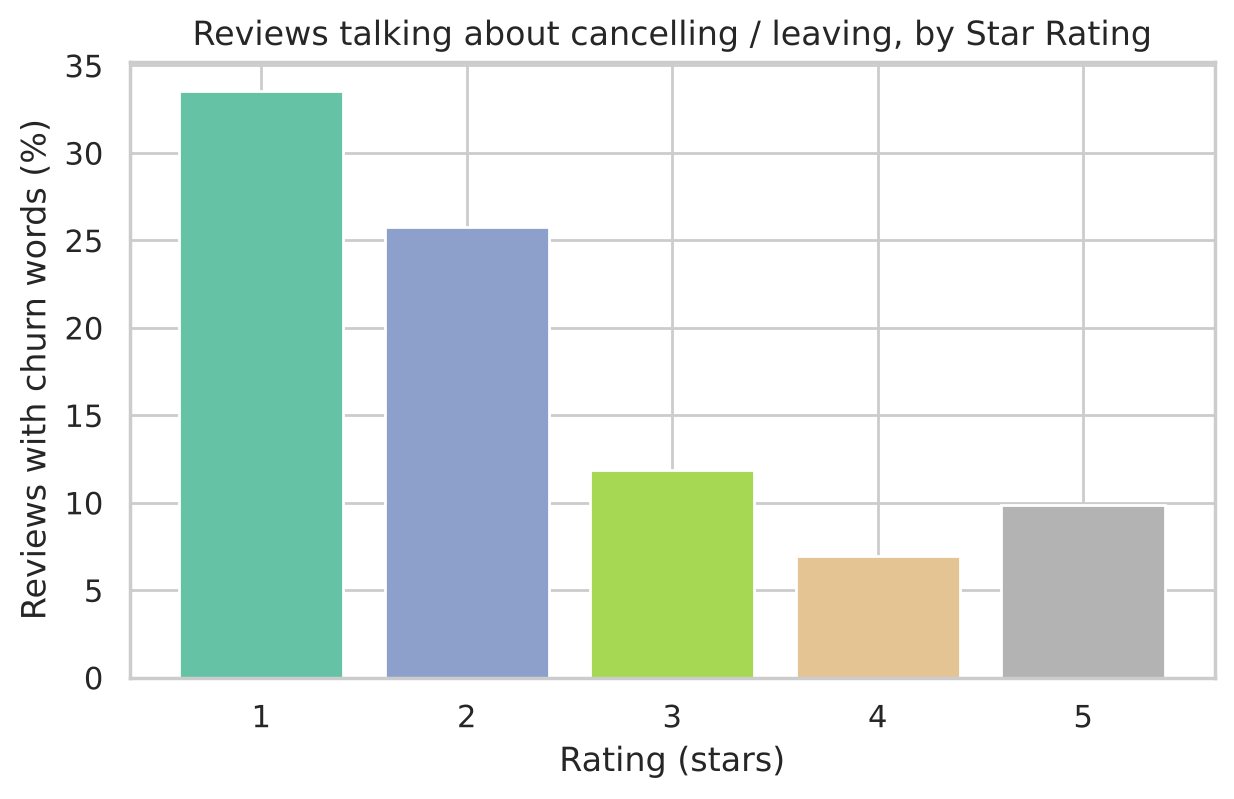

In [28]:
# 4.2 Churn language (cancel / refund / switch words) by Rating
churn_rating = df_visual.groupby('rating')['churn_keyword'].mean() * 100
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_rating)))

plt.figure(figsize=(7, 4))
plt.bar(churn_rating.index.astype(str), churn_rating.values, color=colors)
plt.title('Reviews talking about cancelling / leaving, by Star Rating')
plt.xlabel('Rating (stars)')
plt.ylabel('Reviews with churn words (%)')
plt.show()

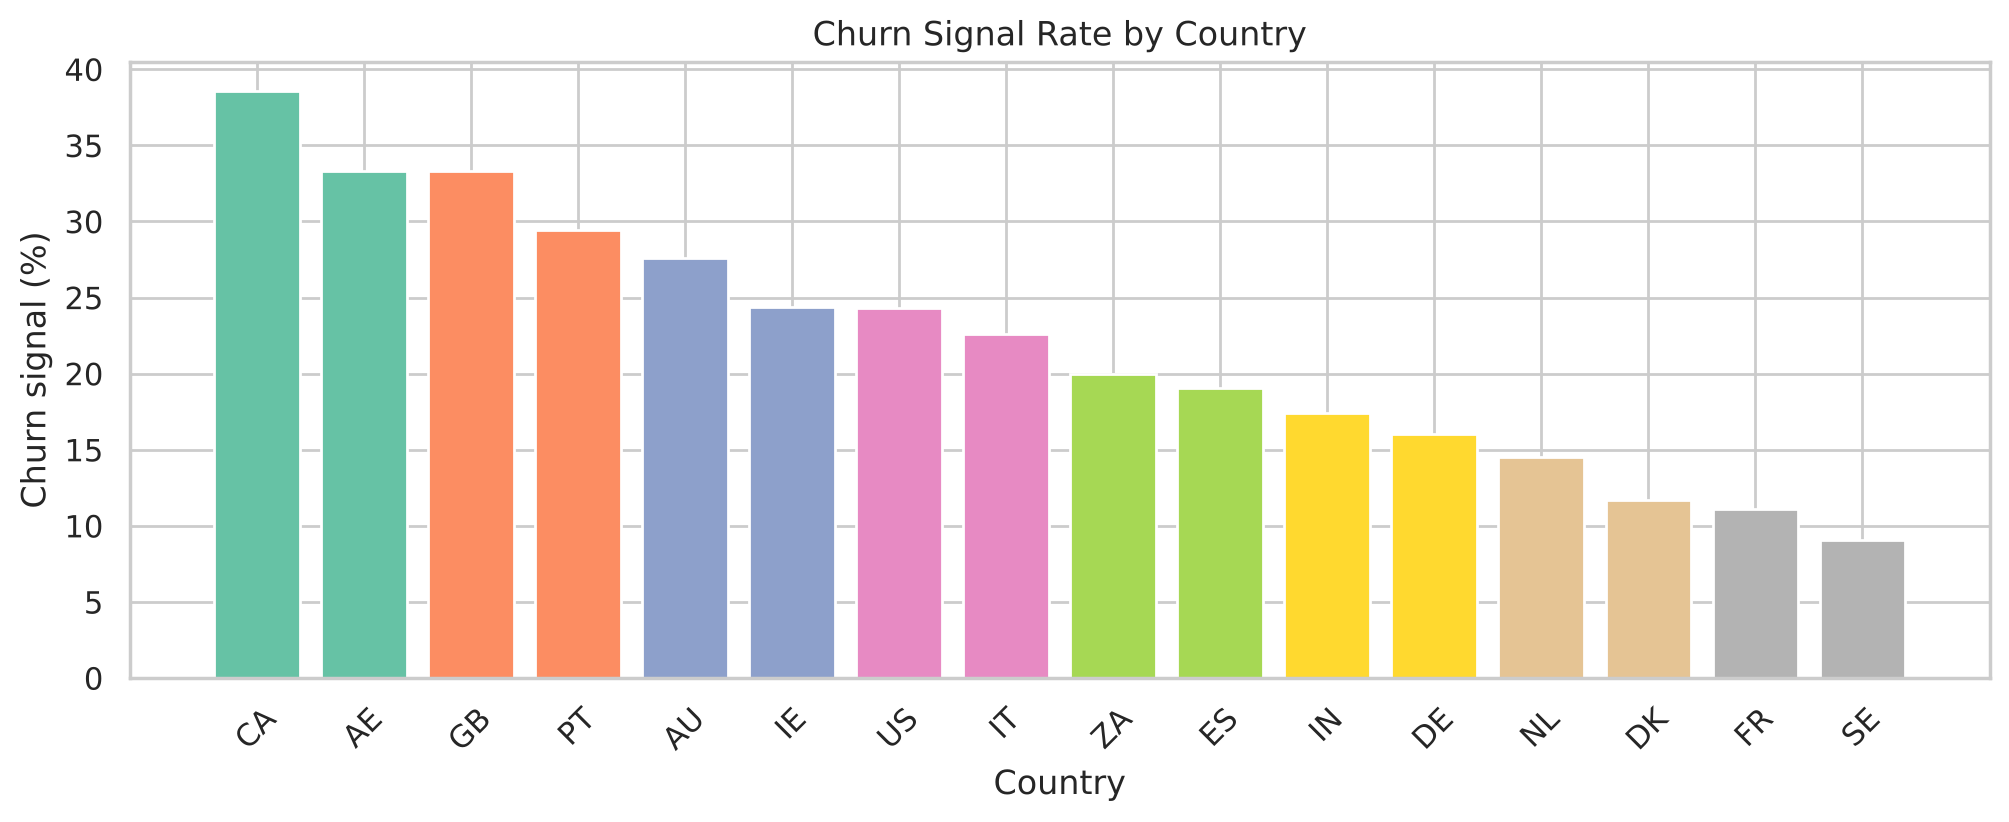

In [29]:
# 4.3 Churn Signal by Country (15+ reviews)
c = by_country.sort_values('churn_signal_pct', ascending=False)
colors = plt.cm.Set2(np.linspace(0, 1, len(c)))

plt.figure(figsize=(12, 4))
plt.bar(c.index, c['churn_signal_pct'], color=colors)
plt.title('Churn Signal Rate by Country')
plt.xlabel('Country')
plt.ylabel('Churn signal (%)')
plt.xticks(rotation=45)
plt.show()

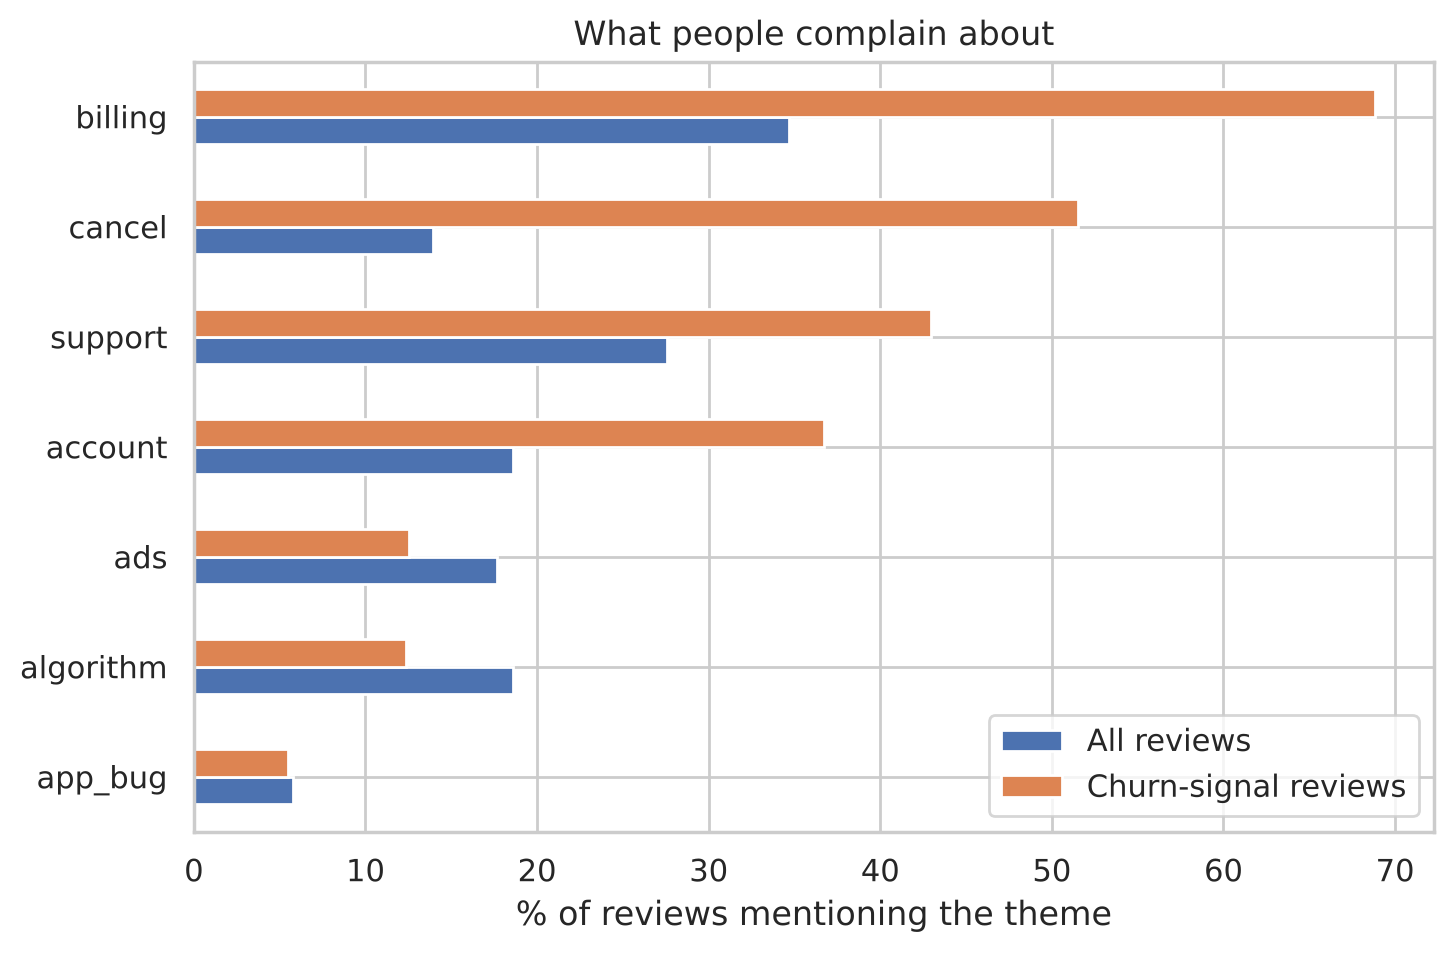

In [30]:
# 4.4 Complaint themes: all reviews vs churn-signal reviews
theme_all   = df_visual[theme_cols].mean() * 100
theme_churn = df_visual.loc[df_visual['churn_signal'] == 1, theme_cols].mean() * 100
theme_cmp = pd.DataFrame({'All reviews': theme_all, 'Churn-signal reviews': theme_churn})
theme_cmp.index = theme_cmp.index.str.replace('theme_', '')
theme_cmp = theme_cmp.sort_values('Churn-signal reviews')

theme_cmp.plot(kind='barh', figsize=(8, 5))
plt.title('What people complain about')
plt.xlabel('% of reviews mentioning the theme')
plt.show()

## Visualization using Seaborn

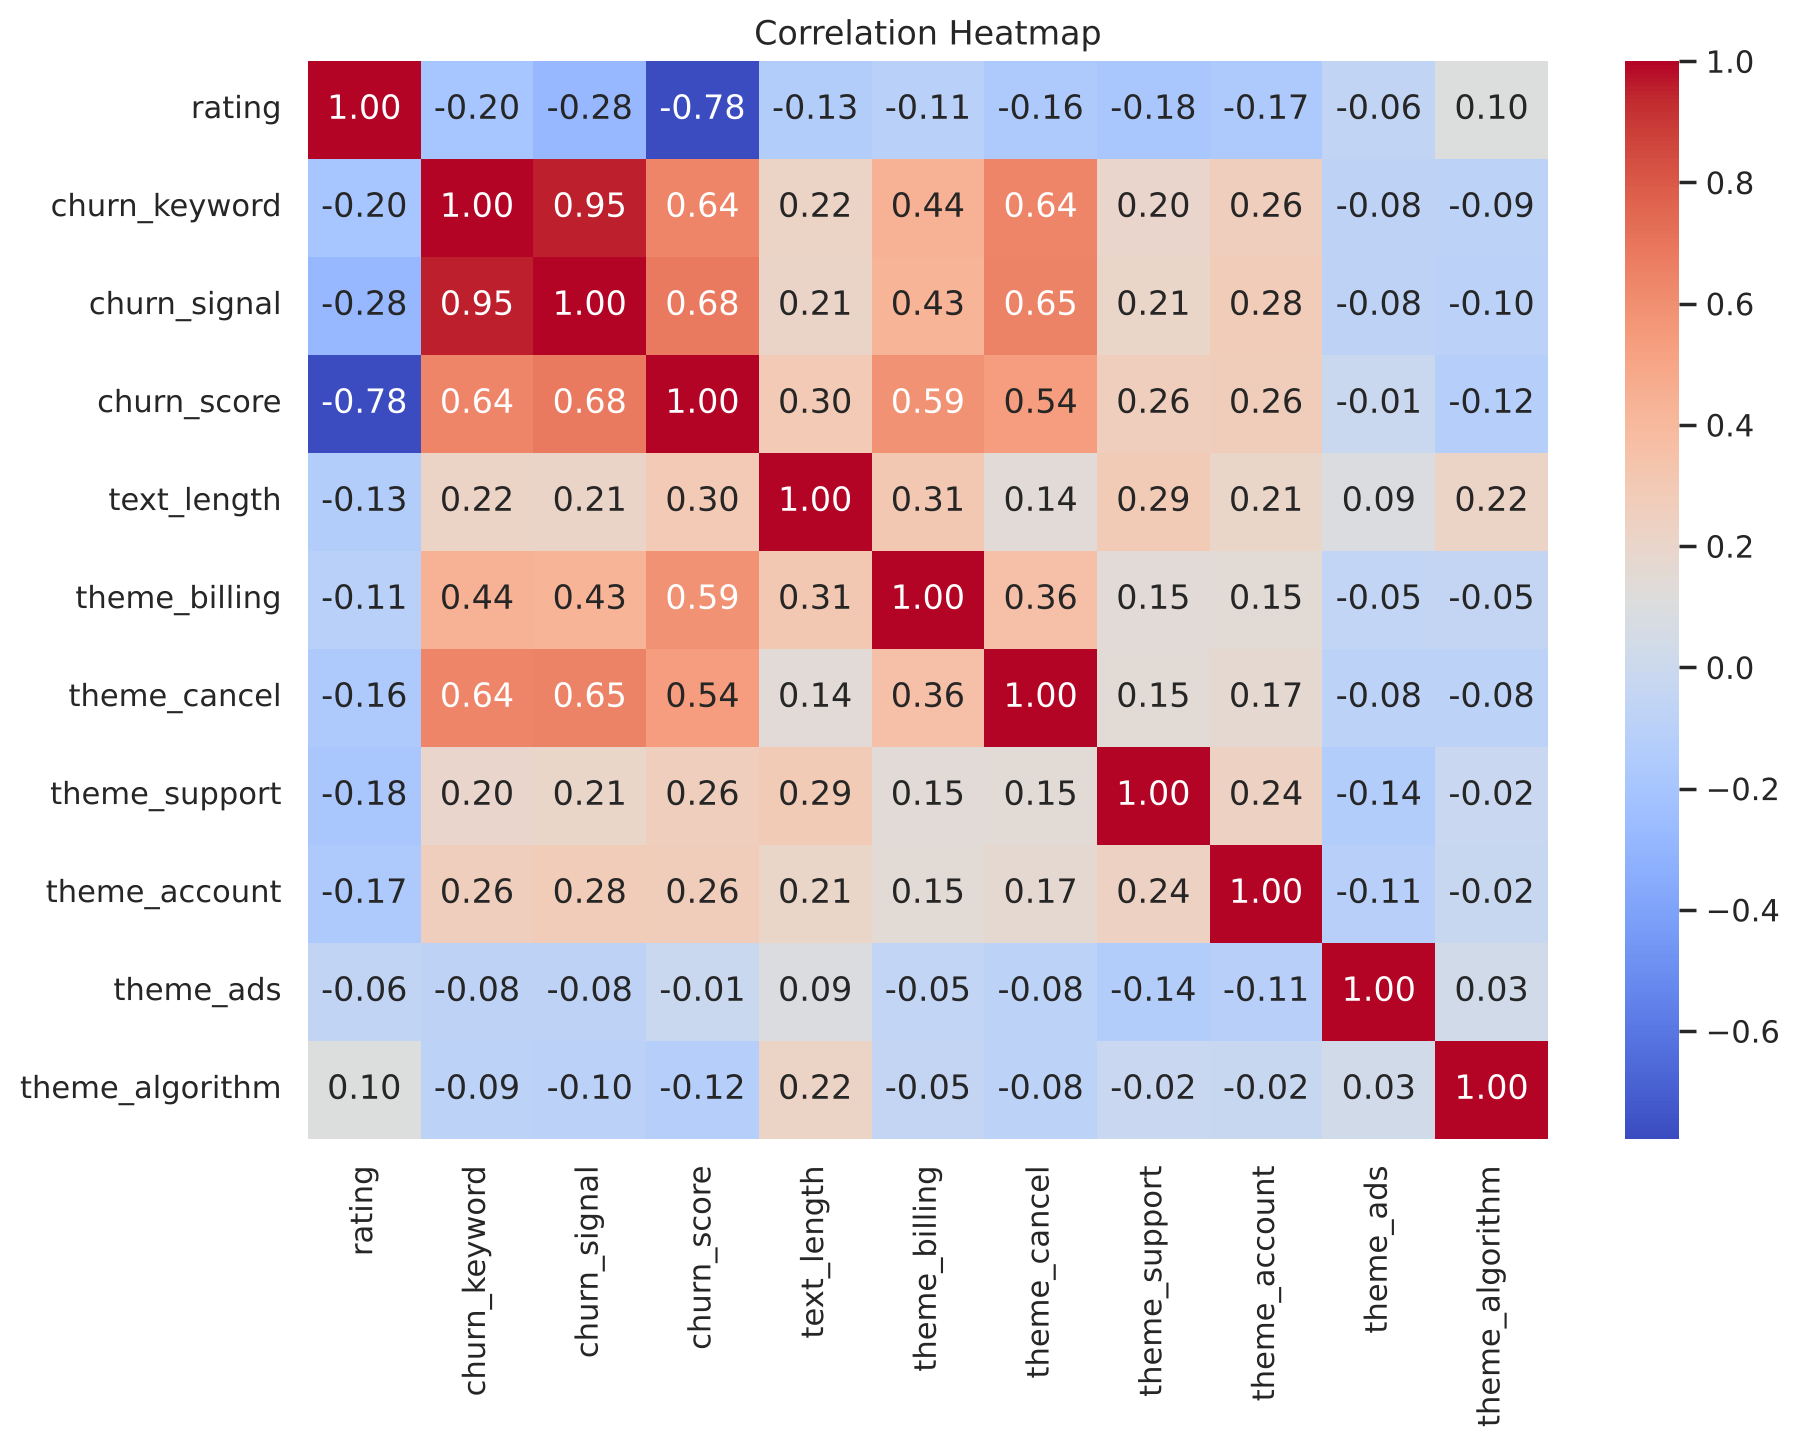

In [31]:
# Heatmap (Correlation Matrix)
num_cols = ['rating', 'churn_keyword', 'churn_signal', 'churn_score', 'text_length',
            'theme_billing', 'theme_cancel', 'theme_support', 'theme_account', 'theme_ads', 'theme_algorithm']

plt.figure(figsize=(10, 7))
sns.heatmap(df_visual[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

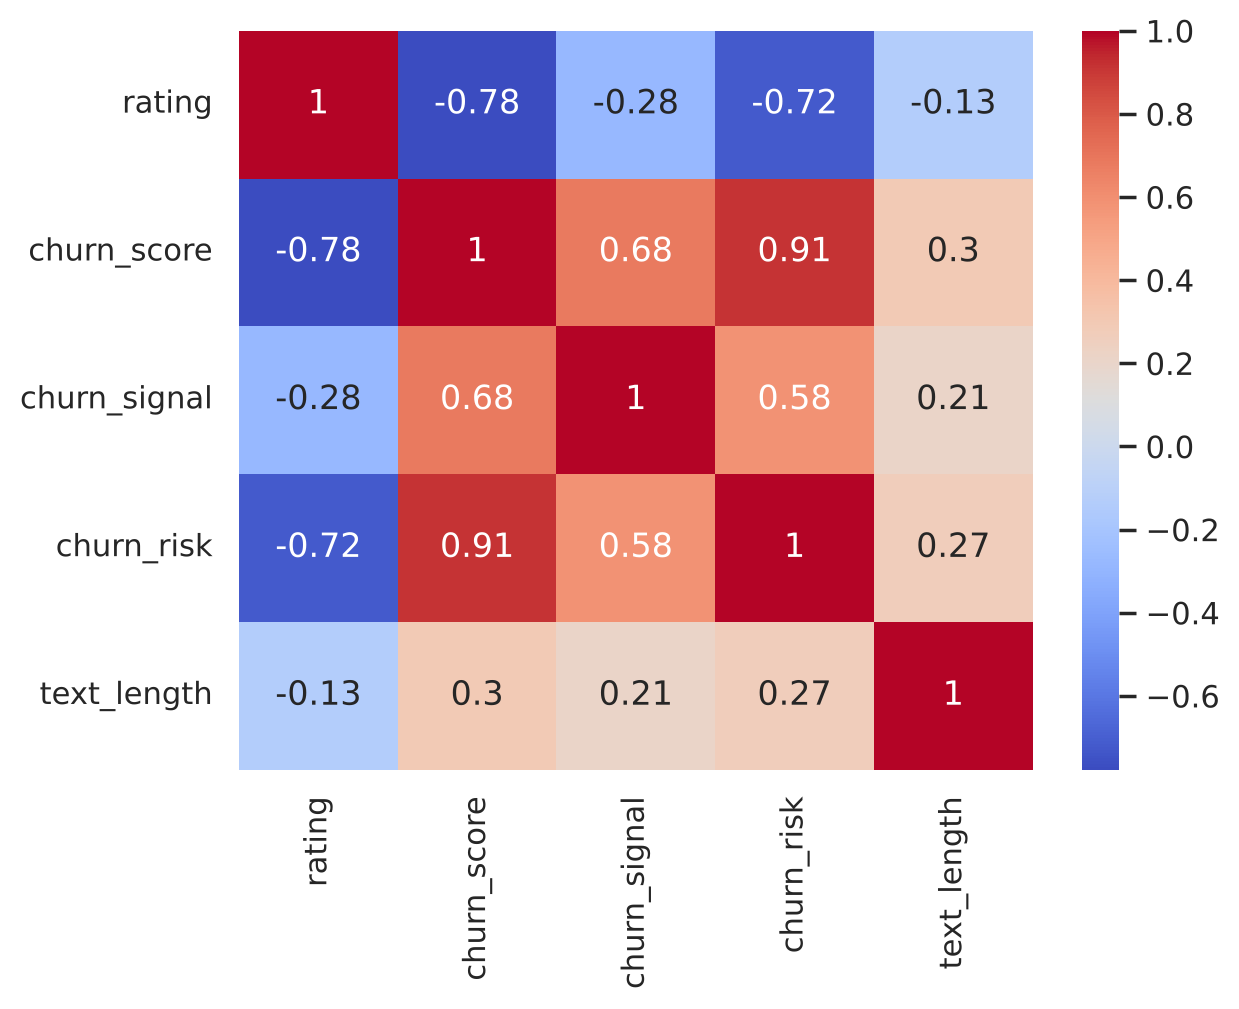

In [32]:
# churn_risk is a category with an order - encode it by priority (not alphabetically)
df_encoded = df_visual[['rating', 'churn_score', 'churn_signal', 'churn_risk', 'text_length']].copy()
df_encoded['churn_risk'] = pd.Categorical(df_encoded['churn_risk'], categories=['low', 'med', 'high'], ordered=True).codes
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm')
plt.show()

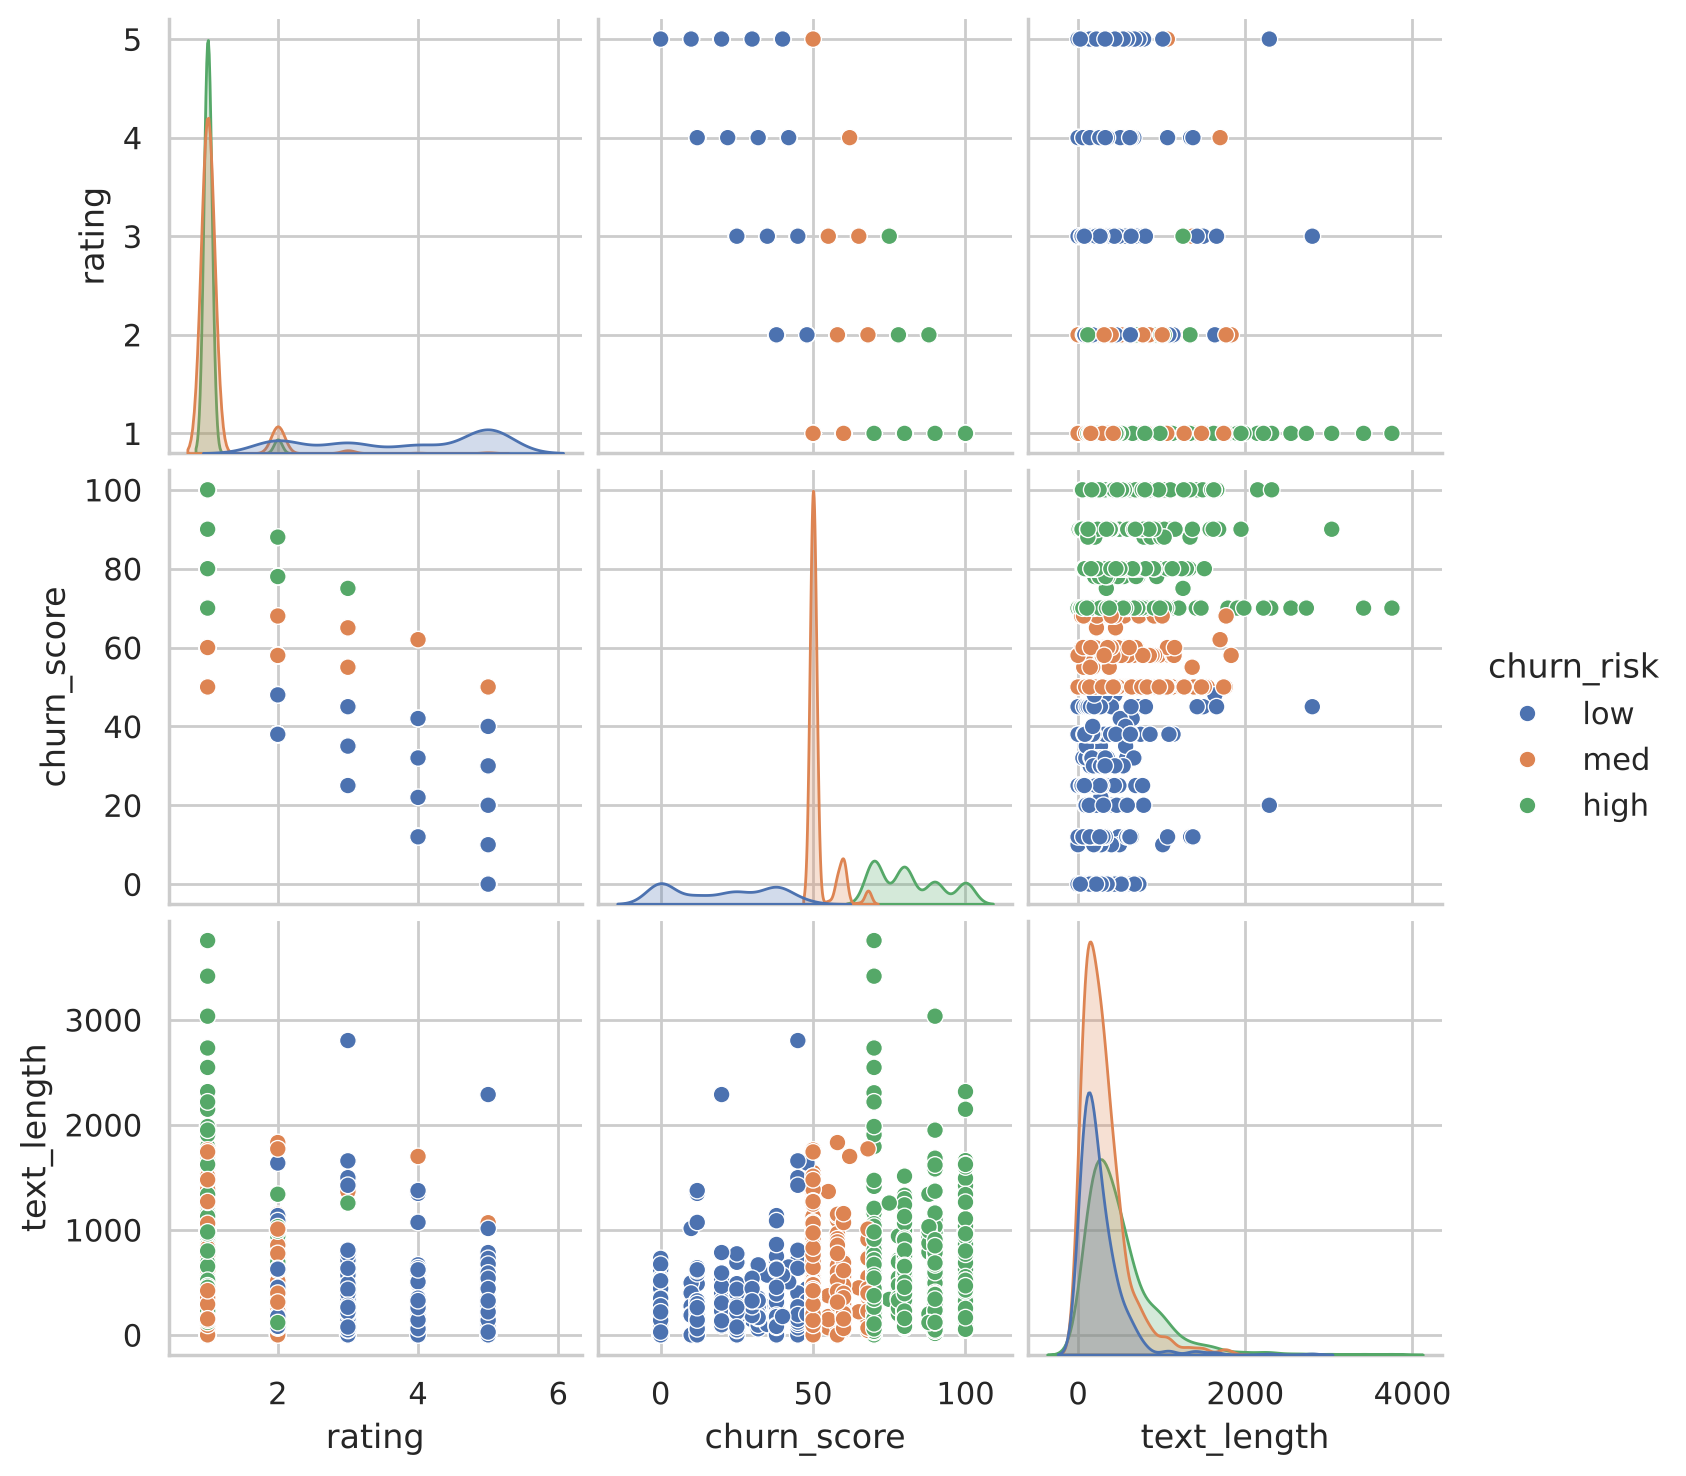

In [33]:
# pairplot - pairwise relationships
sns.pairplot(df_visual[['rating', 'churn_score', 'text_length', 'churn_risk']], hue='churn_risk',
             hue_order=['low', 'med', 'high'])
plt.show()

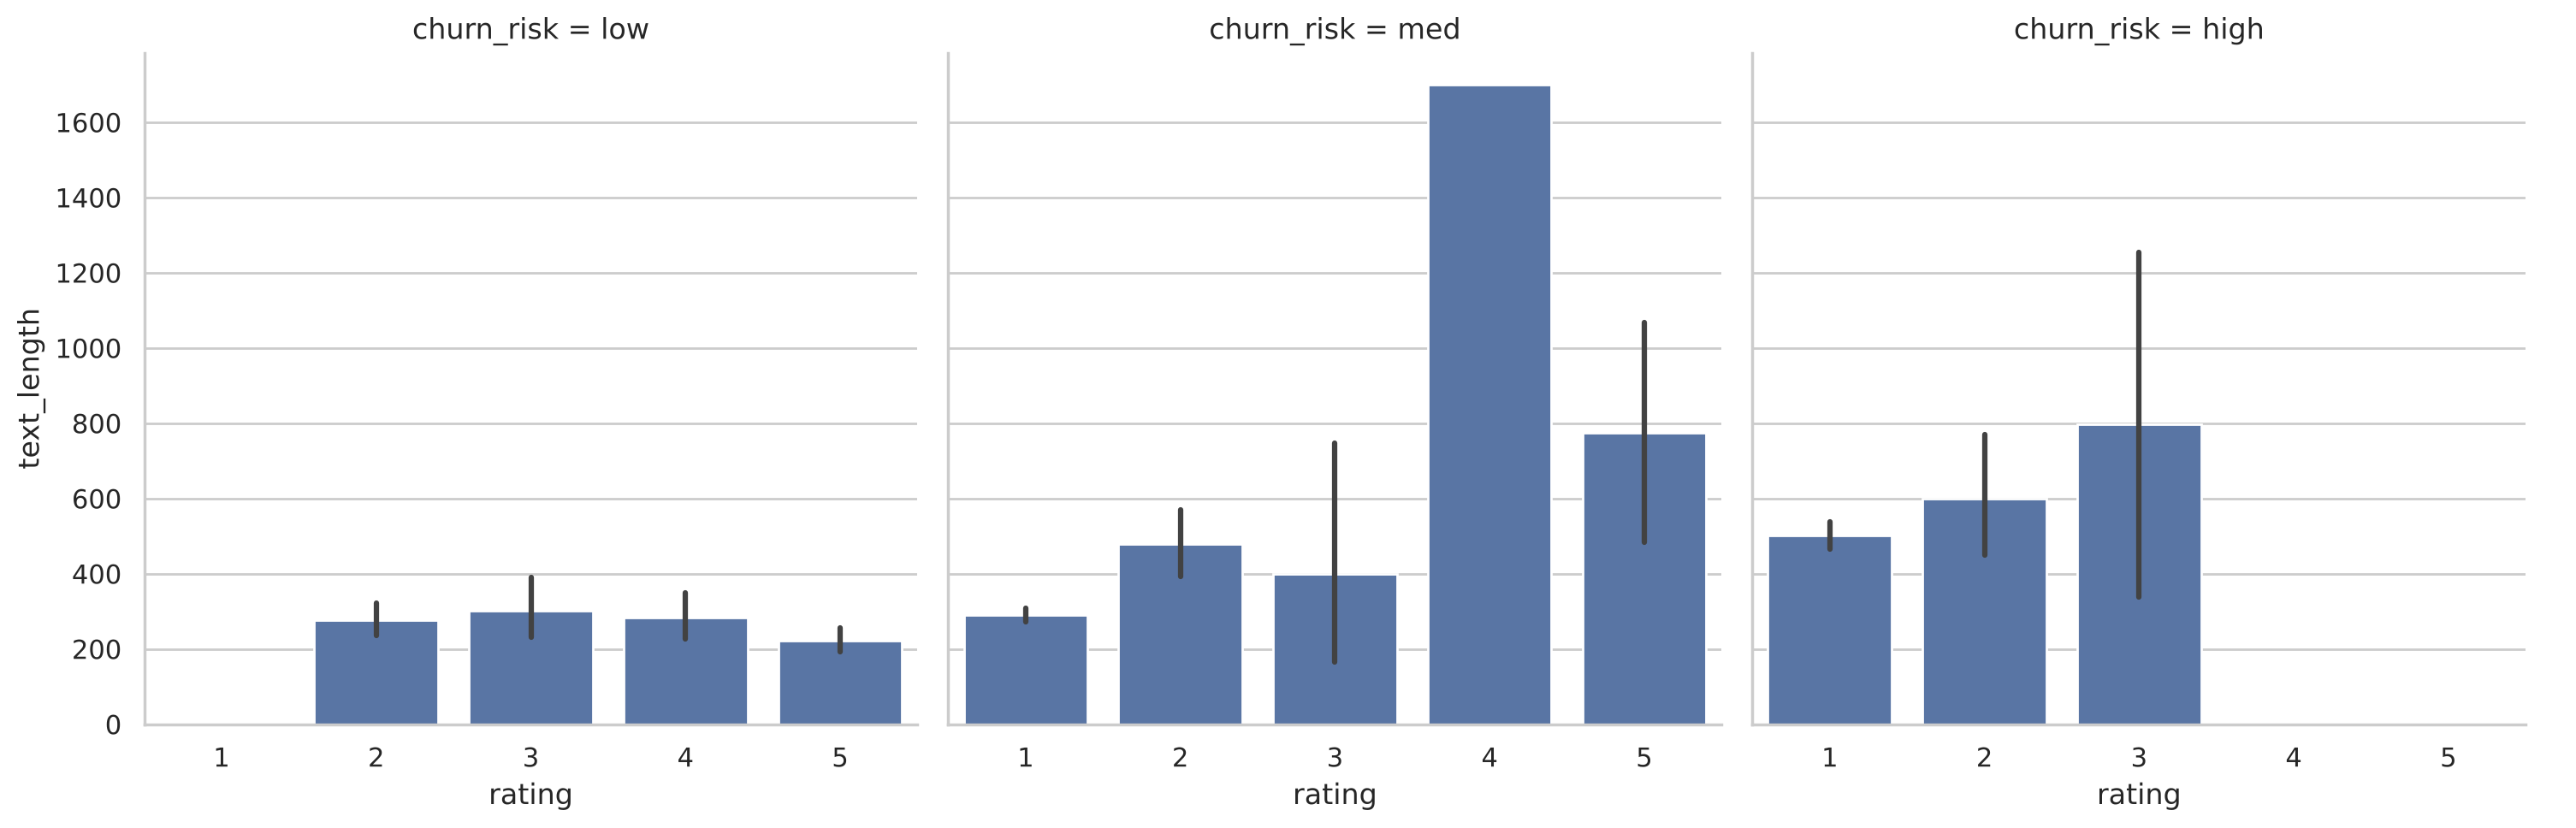

In [34]:
# catplot/Facegrid plot - multi-dim comparison: review length by rating, split by churn_risk
sns.catplot(data=df_visual, x='rating', y='text_length', col='churn_risk',
            col_order=['low', 'med', 'high'], kind='bar')
plt.show()

## Word frequency - what do churn-signal reviewers actually say?

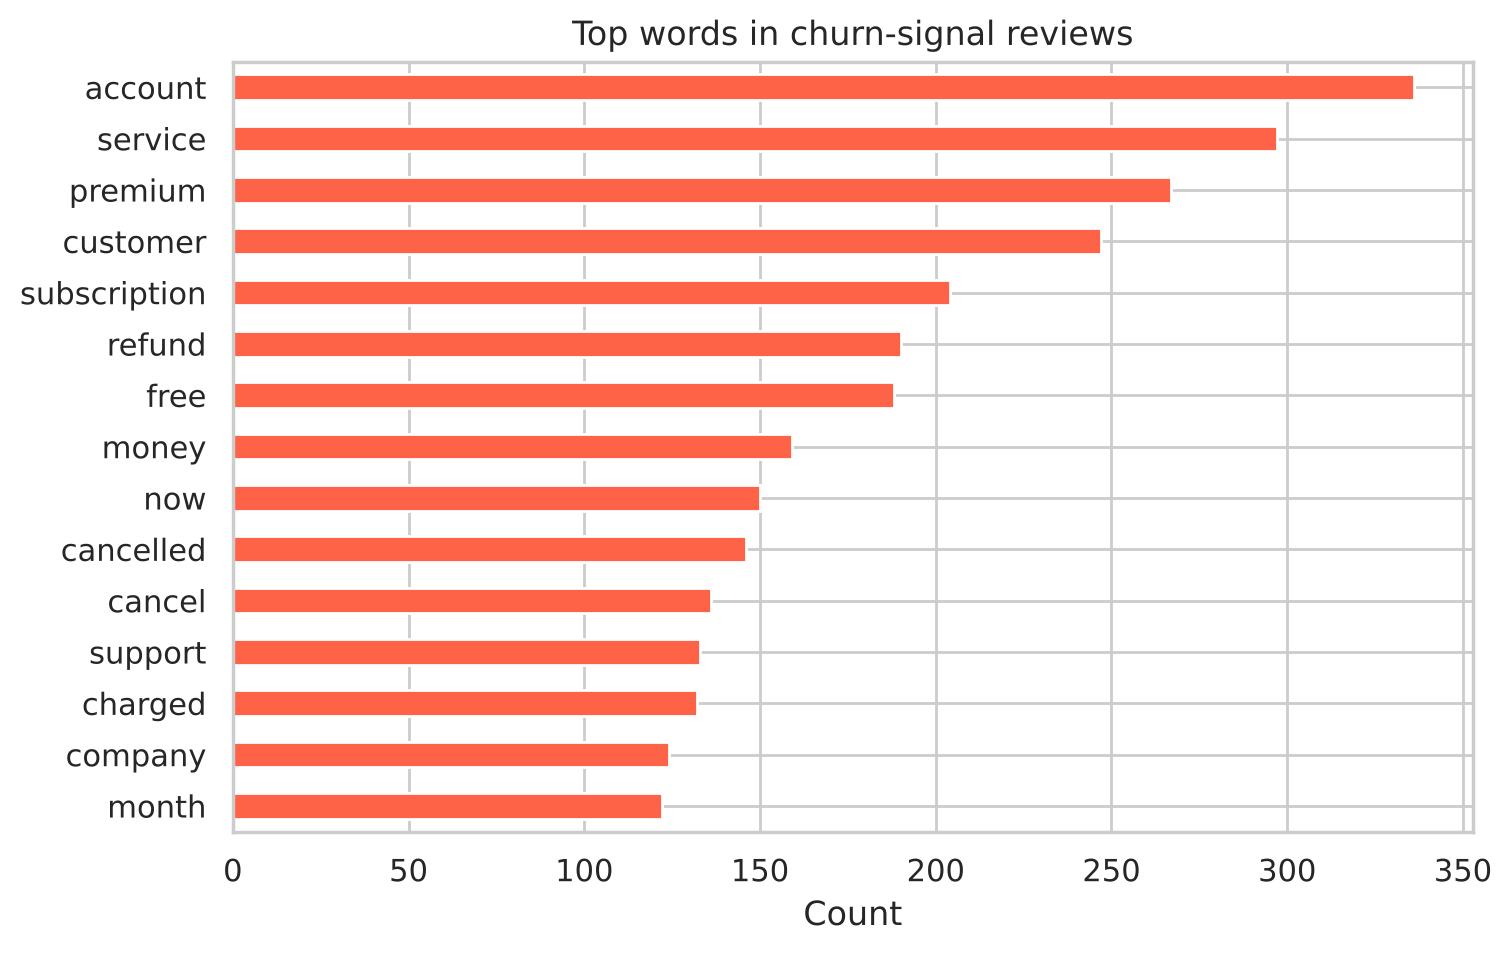

In [35]:
stopwords = set("""the and for that this with have was but not you are they from their has had its out can all one
when what who how them would about there been just than then into more will were your our because even only get got
spotify app music song songs listen listening use used using like very really also still much some any way too them
dont don't didn't doesn't can't won't i'm it's i've i'd it" and a an i it to of in is on at be as my me we so if or no
do did does am by up he she his her him them these those which while after before over again never ever back want""".split())

def top_words(texts, n=15):
    words = re.findall(r"[a-z']{3,}", " ".join(texts))
    words = [w for w in words if w not in stopwords]
    return pd.Series(words).value_counts().head(n)

top_churn = top_words(df_visual.loc[df_visual['churn_signal'] == 1, 'full_text'])

plt.figure(figsize=(8, 5))
top_churn.sort_values().plot(kind='barh', color='tomato')
plt.title('Top words in churn-signal reviews')
plt.xlabel('Count')
plt.show()

## Pivot table

In [36]:
# Pivot Table
pd.pivot_table(df_visual, index='rating', values='churn_signal', aggfunc='mean')

,churn_signal
rating,
1,0.335452
2,0.257576
3,0.000000
4,0.000000
5,0.000000


In [37]:
# pivot table using multiple cols and agg type
pd.pivot_table(
    df_visual,
    index='churn_risk',
    values=['review_id', 'rating', 'churn_signal', 'text_length'],
    aggfunc={
        'review_id': 'nunique',      # number of reviews
        'rating': 'mean',
        'churn_signal': 'mean',
        'text_length': 'mean'
    }
).round(2)

,churn_signal,rating,review_id,text_length
churn_risk,,,,
high,0.68,1.04,622,504.96
low,0.01,3.78,487,258.73
med,0.11,1.10,891,306.83


In [38]:
# number of reviews by year and churn risk level
pd.pivot_table(df_visual, index='review_year', columns='churn_risk', values='review_id', aggfunc='count', fill_value=0)

churn_risk,high,low,med
review_year,,,
2021,26,31,24
2022,72,96,128
2023,69,86,109
2024,115,74,165
2025,163,116,239
2026,177,84,226


## Working with SQL in Python

In [39]:
# put the cleaned data in a SQLite table and query it with SQL
conn = sqlite3.connect('reviews.db')

df_sql = df[['review_id', 'company', 'country', 'rating', 'review_date', 'churn_signal', 'churn_risk']].copy()
df_sql['review_date'] = df_sql['review_date'].dt.strftime('%Y-%m-%d')
df_sql.to_sql('reviews', conn, if_exists='replace', index=False)

query = """
        SELECT country,
               COUNT(*) AS reviews,
               ROUND(AVG(churn_signal) * 100, 1) AS churn_signal_pct,
               ROUND(AVG(rating), 2) AS avg_rating
        FROM reviews
        GROUP BY country
        HAVING COUNT(*) >= 15
        ORDER BY churn_signal_pct DESC
"""
print(pd.read_sql(query, conn))

# always close the conn with db once the task is over
conn.close()

   country  reviews  churn_signal_pct  avg_rating
0       CA       83              38.6        1.31
1       GB      744              33.3        1.54
2       AE       15              33.3        1.33
3       PT       17              29.4        1.71
4       AU       58              27.6        1.81
5       IE       41              24.4        1.73
6       US      440              24.3        1.90
7       IT       31              22.6        1.87
8       ZA       20              20.0        2.00
9       ES       21              19.0        1.57
10      IN       23              17.4        2.13
11      DE       50              16.0        1.94
12      NL       62              14.5        1.42
13      DK       60              11.7        1.43
14      FR       18              11.1        2.94
15      SE       33               9.1        2.39


## 5. Predict, explain and put a price on churn risk

This section turns the review analysis into a retention business case: **predict** who shows a churn signal, **explain** why, estimate the **revenue at risk**, **suggest a retention offer** and show the **expected ROI**.

**What is real and what is assumed**

| Part | Source |
|---|---|
| Reviews, ratings, text, churn signal | Real data (the 2,000 reviews above) |
| Churn probability | Model output, checked on held-out reviews |
| Subscription price, offer costs, offer success rates | **Assumptions** (listed in one place, changeable) |
| "Is this reviewer a paying subscriber?" | Simple text heuristic, not a fact |

A reviewer is used as a stand-in for a customer. Reviews contain no billing or usage records, so nothing here is a real revenue figure for the company.

**Avoiding a circular model.** `churn_signal` is *defined* from the rating and from words like cancel / refund / charged / switch. A model that reads those same words would just rediscover the rule. So the words that define the label (and any mention of star ratings) are removed from the text before modelling. The model then has to find other language that goes with leaving.

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss

SEED = 42

# ---------- ASSUMPTIONS (change these) ----------
MONTHLY_PRICE = 12.99   # USD per month. List price of US Premium Individual as of Nov 2026. Real average revenue per
                        # subscriber is lower (student, family, other countries), see the sensitivity table below.

def money(x):
    return f"${x:,.0f}"

### 5.1 Remove the words that define the label

The model must not see the words used to build the label (otherwise it is circular), so they are masked first. The name of the review website itself is also removed, so it cannot show up in results.

In [41]:
# the review website's own name, built from pieces so the name is never written in this notebook
SITE_NAME = "".join(["trust", "pilot"])
STAR_WORDS = r"\bstars?\b"

def mask_label_words(text):
    """Remove whole words containing the churn keywords, the site name and star-rating words."""
    text = re.sub(r"\w*(?:" + churn_pattern + r")\w*", " ", text)
    text = re.sub(r"\w*" + SITE_NAME + r"\w*", " ", text)
    text = re.sub(STAR_WORDS, " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["text_masked"] = df["full_text"].map(mask_label_words)
y = df["churn_signal"].values

example = df.loc[df["churn_signal"] == 1, ["full_text", "text_masked"]].iloc[0]
print("BEFORE:", example["full_text"][:230])
print("AFTER :", example["text_masked"][:230])

BEFORE: double billing and an exhausting battle for a refund. two £12.99 spotify payments, only three days apart, under separate paypal billing agreements. spotify has now identified a second account linked to my payment details, yet i am
AFTER : double billing and an exhausting battle for a . two £12.99 spotify payments, only three days apart, under separate paypal billing agreements. spotify has now identified a second account linked to my payment details, yet i am still


### 5.2 Predict who shows a churn signal

Logistic regression on TF-IDF word features. I chose it because every word gets one weight, so each prediction can be explained. Its probabilities are **calibrated** (Platt scaling) so that a score of 80% means about 80% of such reviews really carry the signal. All scores use **5-fold cross-validation**: each review is scored by a model that never saw it, so the numbers are honest even with only 2,000 reviews.

In [42]:
def make_vectorizer():
    # words only (token_pattern ignores numbers such as prices)
    return TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english", sublinear_tf=True,
                           token_pattern=r"(?u)\b[a-z][a-z]+\b")

def make_model():
    return make_pipeline(make_vectorizer(),
                         CalibratedClassifierCV(LogisticRegression(C=1.0, max_iter=3000), method="sigmoid", cv=5))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# comparison: with and without masking
p_leaky = cross_val_predict(make_model(), df["full_text"], y, cv=cv, method="predict_proba")[:, 1]
p_oof   = cross_val_predict(make_model(), df["text_masked"], y, cv=cv, method="predict_proba")[:, 1]   # honest score for every review

auc, ap = roc_auc_score(y, p_oof), average_precision_score(y, p_oof)
top100 = y[np.argsort(-p_oof)[:100]].mean()
print(f"Without masking (leaky): AUC {roc_auc_score(y, p_leaky):.3f}   <- inflated, the model reads the label's own words")
print(f"With masking (used)    : AUC {auc:.3f} | average precision {ap:.3f} (random guessing = {y.mean():.3f}) | Brier {brier_score_loss(y, p_oof):.3f}")
print(f"Top 100 highest-risk reviews: {top100:.0%} really carry the churn signal (overall {y.mean():.0%})")

Without masking (leaky): AUC 0.906   <- inflated, the model reads the label's own words
With masking (used)    : AUC 0.799 | average precision 0.642 (random guessing = 0.263) | Brier 0.144
Top 100 highest-risk reviews: 91% really carry the churn signal (overall 26%)


**Can the probabilities be trusted?** A statement like "87% probability" only makes sense if, among reviews scored around 87%, about 87% really carry the signal. The table splits the reviews into 10 equal groups by score and compares the average predicted risk with the real rate.

            reviews  avg_predicted  actual_rate
risk_group                                     
1               200          0.039        0.030
2               200          0.071        0.080
3               200          0.103        0.095
4               200          0.132        0.160
5               200          0.165        0.180
6               200          0.211        0.180
7               200          0.280        0.265
8               200          0.378        0.360
9               200          0.533        0.505
10              200          0.770        0.775


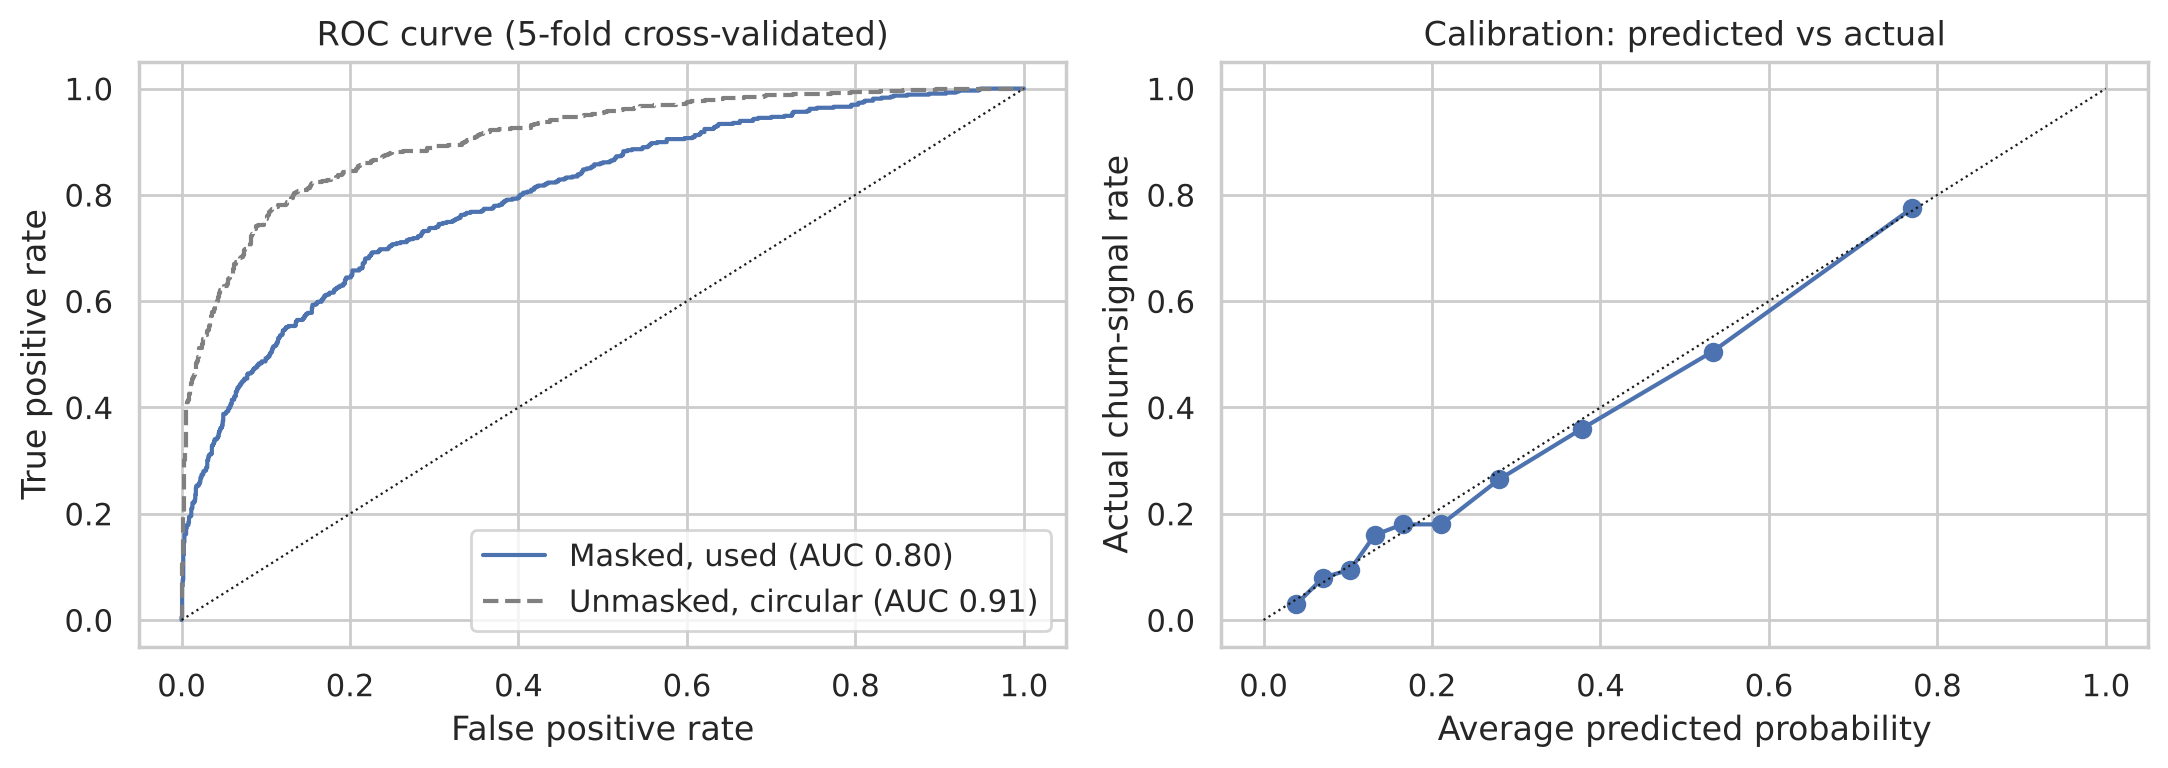

In [43]:
calib = pd.DataFrame({"p": p_oof, "actual": y})
calib["risk_group"] = pd.qcut(calib["p"], 10, labels=False, duplicates="drop") + 1
calib_tbl = calib.groupby("risk_group").agg(reviews=("p", "size"), avg_predicted=("p", "mean"),
                                            actual_rate=("actual", "mean")).round(3)
print(calib_tbl)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y, p_oof)
fpr2, tpr2, _ = roc_curve(y, p_leaky)
ax[0].plot(fpr, tpr, label=f"Masked, used (AUC {auc:.2f})")
ax[0].plot(fpr2, tpr2, "--", color="grey", label=f"Unmasked, circular (AUC {roc_auc_score(y, p_leaky):.2f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[0].set(title="ROC curve (5-fold cross-validated)", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend()
ax[1].plot(calib_tbl["avg_predicted"], calib_tbl["actual_rate"], "o-")
ax[1].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[1].set(title="Calibration: predicted vs actual", xlabel="Average predicted probability", ylabel="Actual churn-signal rate")
plt.tight_layout()
plt.show()

### 5.3 Explain why

Overall: the words with the biggest positive and negative weights. For one review: each word's contribution is `word weight x how strongly it appears in that review`, so the largest positive contributions are the reasons that review scores high. (The weights come from a plain logistic regression fitted on all reviews; the probabilities above stay calibrated and cross-validated.)

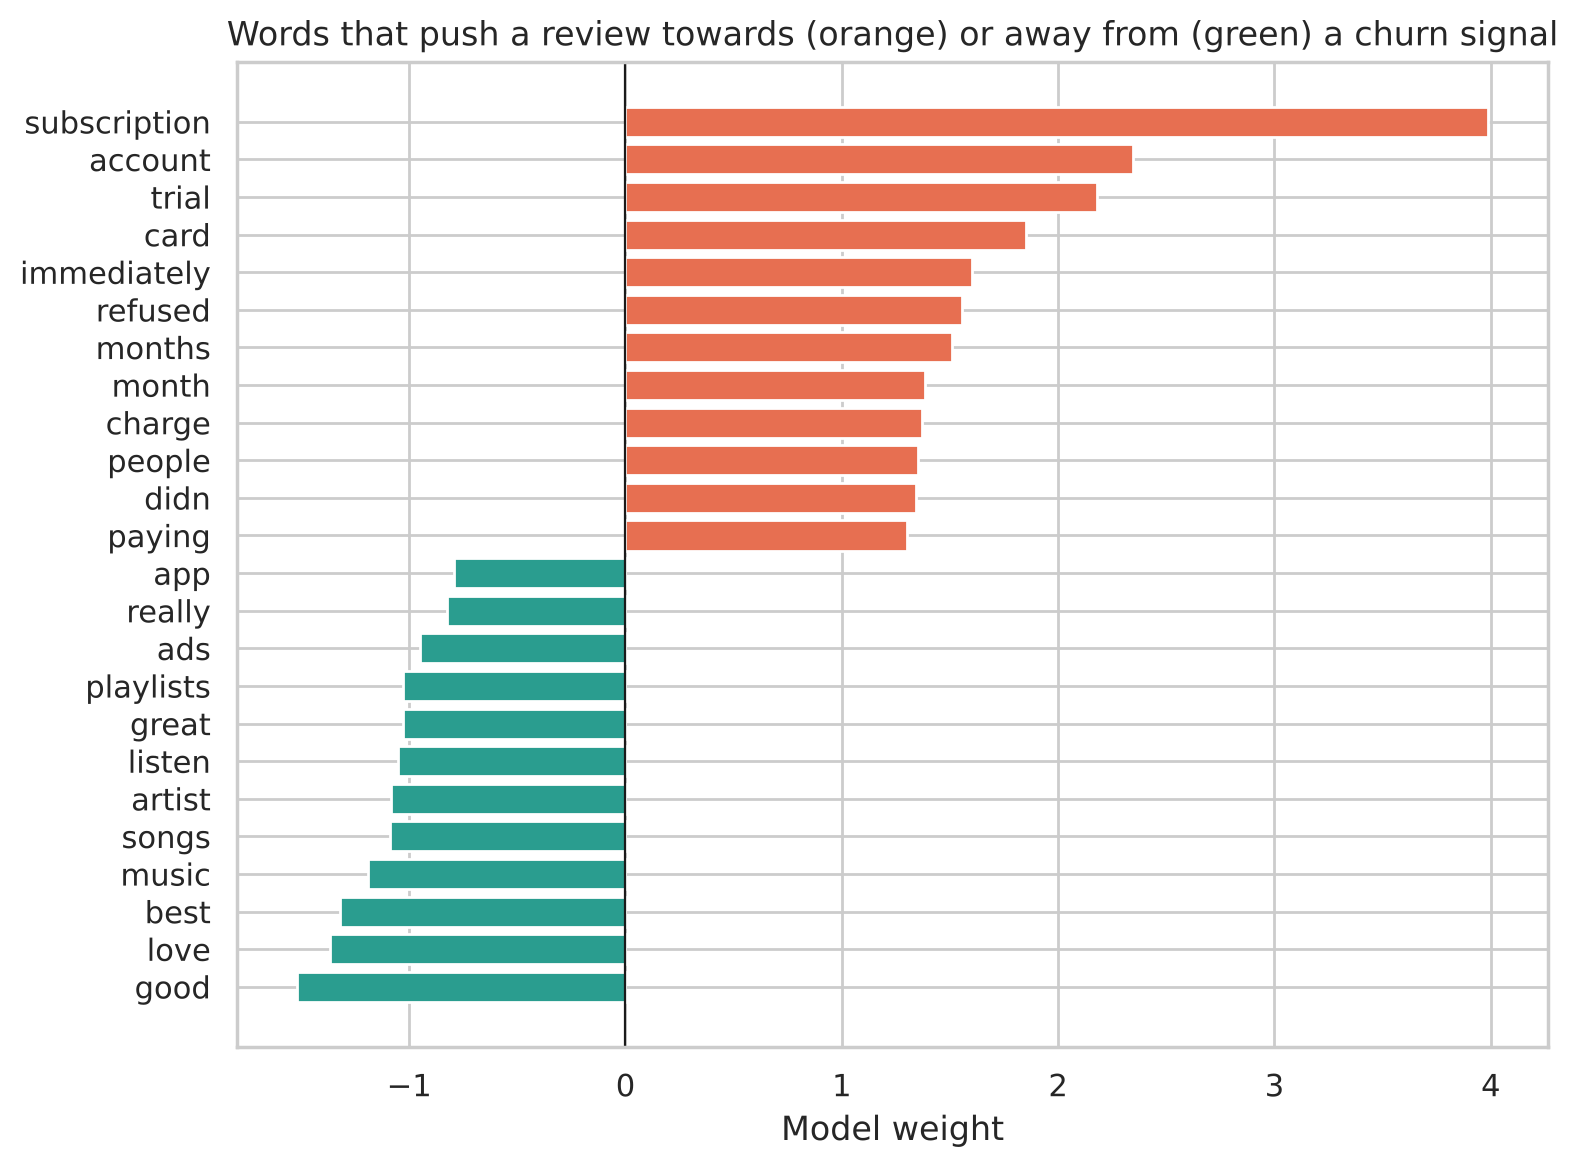

In [44]:
vec = make_vectorizer().fit(df["text_masked"])
X_all = vec.transform(df["text_masked"])
clf = LogisticRegression(C=1.0, max_iter=3000).fit(X_all, y)
vocab = np.array(vec.get_feature_names_out())
coef = clf.coef_[0]

order = np.argsort(coef)
top_neg, top_pos = order[:12], order[::-1][:12]
plot_idx = np.concatenate([top_neg, top_pos[::-1]])
plt.figure(figsize=(8, 6))
plt.barh(vocab[plot_idx], coef[plot_idx], color=["#2a9d8f" if c < 0 else "#e76f51" for c in coef[plot_idx]])
plt.axvline(0, color="k", lw=0.8)
plt.title("Words that push a review towards (orange) or away from (green) a churn signal")
plt.xlabel("Model weight")
plt.tight_layout()
plt.show()

def top_terms(i, k=4):
    """Words in review i that contribute most to its churn probability."""
    row = X_all[i]
    contrib = row.data * coef[row.indices]
    best = np.argsort(-contrib)[:k]
    return [vocab[row.indices[j]] for j in best if contrib[j] > 0]

### 5.4 Revenue at risk

**Revenue at risk = churn probability x 12 months of subscription price.** Only reviewers who sound like paying subscribers count (they mention premium, subscription, paid, renew, family plan, monthly and so on). Someone who only complains about ads on the free tier has no revenue to lose. This flag is a text heuristic and an assumption.

In [45]:
PAYING_WORDS = r"premium|subscri|\bpaid\b|paying|\bfamily\b|\bduo\b|renew|membership|per month|a month|monthly|\bplan\b"
df["likely_paying"] = df["full_text"].str.contains(PAYING_WORDS, regex=True)
print(f"Reviews that sound like paying subscribers: {df['likely_paying'].mean():.0%}")

base = pd.DataFrame({"review_id": df["review_id"], "country": df["country"], "rating": df["rating"],
                     "churn_signal": y, "churn_prob": p_oof, "likely_paying": df["likely_paying"]})

# main complaint theme of each review = the theme (among those it mentions) most linked to the churn signal
theme_rate = {t: df.loc[df["theme_" + t] == 1, "churn_signal"].mean() for t in themes}
print("Churn-signal rate when the theme is mentioned:", {t: round(float(r), 2) for t, r in sorted(theme_rate.items(), key=lambda kv: -kv[1])})
theme_names = list(themes)
present = df[["theme_" + t for t in theme_names]].to_numpy() * np.array([theme_rate[t] for t in theme_names])
base["main_theme"] = np.where(present.max(axis=1) > 0, np.array(theme_names)[present.argmax(axis=1)], "none")
base["main_theme"].value_counts()

Reviews that sound like paying subscribers: 43%
Churn-signal rate when the theme is mentioned: {'cancel': 0.97, 'billing': 0.52, 'account': 0.52, 'support': 0.41, 'app_bug': 0.25, 'ads': 0.19, 'algorithm': 0.17}


main_theme
none         500
billing      480
cancel       279
support      205
ads          199
account      163
algorithm    137
app_bug       37
Name: count, dtype: int64

### 5.5 Retention offers (assumptions)

Each offer is matched to the review's **main complaint theme**. The costs and success rates are **assumptions**, not measured values. A real A/B test (offer vs no offer) would replace them.

In [46]:
# ---------- ASSUMPTIONS: cost in USD (price = monthly price) and share of at-risk customers the offer keeps ----------
OFFERS = {
    "cancel":    dict(name="Retention call + 25% off for 3 months",                   success=0.15, cost=lambda price: 0.25 * price * 3 + 3.0),
    "billing":   dict(name="Fast refund review + 1 month free",                        success=0.25, cost=lambda price: price + 3.0),
    "account":   dict(name="Priority account-recovery agent",                          success=0.30, cost=lambda price: 8.0),
    "support":   dict(name="Callback within 24h + $5 credit",                          success=0.25, cost=lambda price: 9.0),
    "app_bug":   dict(name="Bug follow-up + $3 credit",                                success=0.20, cost=lambda price: 5.0),
    "ads":       dict(name="50% off for 2 months",                                     success=0.15, cost=lambda price: price),
    "algorithm": dict(name="Personalised discovery tips email",                        success=0.08, cost=lambda price: 0.5),
    "none":      dict(name="Apology + feedback survey",                                success=0.05, cost=lambda price: 0.5),
}
pd.DataFrame([{"theme": k, "offer": v["name"], "assumed_success_rate": v["success"]} for k, v in OFFERS.items()])

,theme,offer,assumed_success_rate
0,cancel,Retention call + 25% off for 3 months,0.15
1,billing,Fast refund review + 1 month free,0.25
2,account,Priority account-recovery agent,0.30
3,support,Callback within 24h + $5 credit,0.25
4,app_bug,Bug follow-up + $3 credit,0.20
5,ads,50% off for 2 months,0.15
6,algorithm,Personalised discovery tips email,0.08
7,none,Apology + feedback survey,0.05


### 5.6 Expected ROI

- **Expected revenue saved** = churn probability x offer success rate x 12 months of price
- **Offer cost** is paid for every customer targeted, whether or not they would have left
- **Net benefit** = expected saved - cost. A customer is targeted only when net benefit is positive
- **ROI** = net benefit / cost

In [47]:
def build_scored(price=MONTHLY_PRICE, success_mult=1.0):
    s = base.copy()
    s["annual_revenue"] = np.where(s["likely_paying"], price * 12, 0.0)
    s["revenue_at_risk"] = s["churn_prob"] * s["annual_revenue"]
    s["offer"] = s["main_theme"].map(lambda t: OFFERS[t]["name"])
    s["offer_cost"] = s["main_theme"].map(lambda t: OFFERS[t]["cost"](price))
    s["success_rate"] = (s["main_theme"].map(lambda t: OFFERS[t]["success"]) * success_mult).clip(upper=1)
    s["expected_saved"] = s["churn_prob"] * s["success_rate"] * s["annual_revenue"]
    s["net_benefit"] = s["expected_saved"] - s["offer_cost"]
    s["target"] = s["net_benefit"] > 0
    return s

def campaign(s):
    t = s[s["target"]]
    cost, saved = t["offer_cost"].sum(), t["expected_saved"].sum()
    return {"targeted": len(t), "cost": cost, "saved": saved, "net": saved - cost, "roi": (saved - cost) / cost if cost else np.nan}

scored = build_scored()
c = campaign(scored)
summary = pd.Series({
    "reviews scored": len(scored),
    "likely paying subscribers": int(scored["likely_paying"].sum()),
    "revenue at risk (all)": money(scored["revenue_at_risk"].sum()),
    "reviews targeted with an offer": c["targeted"],
    "campaign cost": money(c["cost"]),
    "expected revenue saved": money(c["saved"]),
    "net benefit": money(c["net"]),
    "ROI": f"{c['roi']:.1f}x"})
summary.to_frame(f"at ${MONTHLY_PRICE}/month")

,at $12.99/month
reviews scored,2000
likely paying subscribers,860
revenue at risk (all),"$49,669"
reviews targeted with an offer,445
campaign cost,"$4,139"
expected revenue saved,"$6,990"
net benefit,"$2,851"
ROI,0.7x


**How sensitive is the ROI to the assumptions?** Both inputs are guesses, so the tables show net benefit and ROI for different prices (real average revenue per subscriber is lower than the list price) and different offer success rates (1.00x = the assumed rates). The targeting rule is re-applied in every cell.

In [48]:
prices, mults = [4.0, 6.5, 9.75, 12.99], [0.5, 1.0, 1.5]
net_tbl = pd.DataFrame({f"success {m:.1f}x": [campaign(build_scored(p, m))["net"] for p in prices] for m in mults},
                       index=pd.Index(prices, name="monthly price ($)")).round(0)
roi_tbl = pd.DataFrame({f"success {m:.1f}x": [campaign(build_scored(p, m))["roi"] for p in prices] for m in mults},
                       index=pd.Index(prices, name="monthly price ($)")).round(2)
print("Net benefit (USD per year). The targeting rule only picks customers with positive expected value, so this is never negative; near 0 means the campaign barely pays off:")
print(net_tbl)
print("\nROI (x) - can fall as success rises, because more marginal customers become worth targeting:")
print(roi_tbl)

Net benefit (USD per year). The targeting rule only picks customers with positive expected value, so this is never negative; near 0 means the campaign barely pays off:
                   success 0.5x  success 1.0x  success 1.5x
monthly price ($)                                          
4.00                        2.0         181.0         987.0
6.50                       13.0         771.0        2460.0
9.75                      106.0        1767.0        4575.0
12.99                     287.0        2851.0        6756.0

ROI (x) - can fall as success rises, because more marginal customers become worth targeting:
                   success 0.5x  success 1.0x  success 1.5x
monthly price ($)                                          
4.00                       0.38          0.20          0.51
6.50                       0.30          0.37          0.75
9.75                       0.26          0.55          0.99
12.99                      0.41          0.69          1.16


                  reviews revenue_at_risk  actual_signal_rate
risk_band                                                    
Low (<20%)           1054          $5,697                0.11
Medium (20-40%)       488         $10,764                0.26
High (40-60%)         235         $11,994                0.48
Very high (60%+)      223         $21,215                0.76


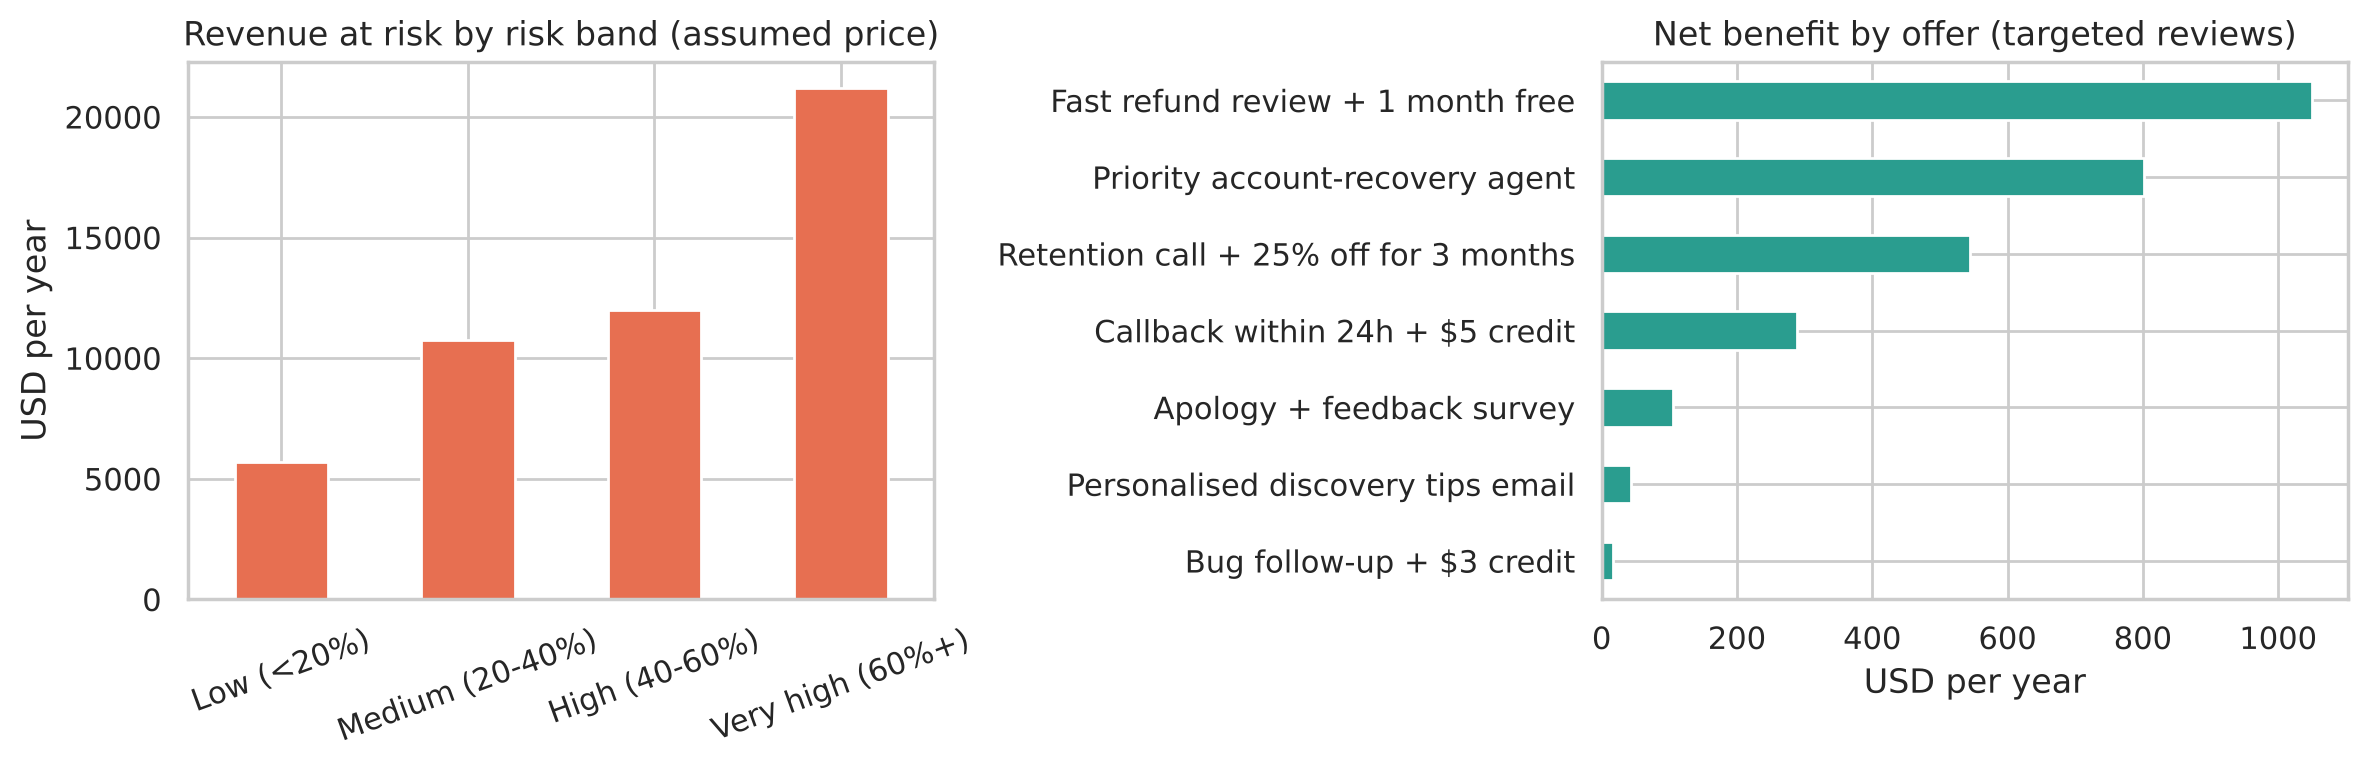

In [49]:
band_labels = ["Low (<20%)", "Medium (20-40%)", "High (40-60%)", "Very high (60%+)"]
scored["risk_band"] = pd.cut(scored["churn_prob"], [0, 0.2, 0.4, 0.6, 1.0], labels=band_labels)
band = scored.groupby("risk_band", observed=True).agg(reviews=("review_id", "size"), revenue_at_risk=("revenue_at_risk", "sum"),
                                                      actual_signal_rate=("churn_signal", "mean")).round(2)
print(band.assign(revenue_at_risk=band["revenue_at_risk"].map(money)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
scored.groupby("risk_band", observed=True)["revenue_at_risk"].sum().plot.bar(ax=ax[0], color="#e76f51")
ax[0].set(title="Revenue at risk by risk band (assumed price)", ylabel="USD per year", xlabel="")
ax[0].tick_params(axis="x", rotation=20)
net_by_offer = scored[scored["target"]].groupby("offer")["net_benefit"].sum().sort_values()
net_by_offer.plot.barh(ax=ax[1], color="#2a9d8f")
ax[1].set(title="Net benefit by offer (targeted reviews)", xlabel="USD per year", ylabel="")
plt.tight_layout()
plt.show()

### 5.7 Single-review demo

The function below gives the one-line story for any review: probability, reasons, revenue at risk, recommended offer and expected ROI.

In [50]:
SITE_RE = re.compile(r"\w*" + SITE_NAME + r"\w*", flags=re.I)

def explain_review(review_id, chars=170):
    i = df.index[df["review_id"] == review_id][0]
    r = scored.iloc[i]
    excerpt = SITE_RE.sub("[site]", str(df.loc[i, "text"] or df.loc[i, "title"]))[:chars].replace("\n", " ")
    roi = (r["expected_saved"] - r["offer_cost"]) / r["offer_cost"]
    print(f"Review {r['review_id'][:8]}... | {r['country']} | {r['rating']} star(s)")
    print(f"  Churn probability : {r['churn_prob']:.0%}")
    print(f"  Why               : words driving the score: {', '.join(top_terms(i)) or 'n/a'} | main complaint theme: {r['main_theme']}")
    print(f"  Revenue at risk   : {money(r['revenue_at_risk'])} of {money(r['annual_revenue'])} annual revenue (assumed price ${MONTHLY_PRICE}/month)")
    print(f"  Recommended offer : {r['offer']} (cost {money(r['offer_cost'])}, assumed success {r['success_rate']:.0%})")
    print(f"  Expected saved    : {money(r['expected_saved'])} | ROI {roi:.1f}x")
    print(f"  Review starts     : \"{excerpt}...\"")

cand = scored[scored["likely_paying"] & scored["target"] & (scored["main_theme"] != "none")]
demo_id = cand.loc[(cand["churn_prob"] - 0.85).abs().idxmin(), "review_id"]
explain_review(demo_id)

Review 6a98e337... | FI | 1 star(s)
  Churn probability : 85%
  Why               : words driving the score: subscription, month, account, days | main complaint theme: billing
  Revenue at risk   : $133 of $156 annual revenue (assumed price $12.99/month)
  Recommended offer : Fast refund review + 1 month free (cost $16, assumed success 25%)
  Expected saved    : $33 | ROI 1.1x
  Review starts     : "The 3-month premium subscription lasted only 3 days. Customer service claims the account had been used previously, which is not true...."


In [51]:
# Portfolio-level version of the same story (this is where larger amounts come from)
t = scored[scored["target"]]
by_offer = t.groupby("offer").agg(reviews=("review_id", "size"), cost=("offer_cost", "sum"),
                                  expected_saved=("expected_saved", "sum"), revenue_at_risk=("revenue_at_risk", "sum"))
by_offer["roi_x"] = ((by_offer["expected_saved"] - by_offer["cost"]) / by_offer["cost"]).round(1)
for col in ["cost", "expected_saved", "revenue_at_risk"]:
    by_offer[col] = by_offer[col].map(money)
print(by_offer.sort_values("reviews", ascending=False))

cols = ["review_id", "country", "rating", "churn_prob", "likely_paying", "main_theme", "revenue_at_risk",
        "offer", "offer_cost", "expected_saved", "net_benefit", "target"]
scored.sort_values("revenue_at_risk", ascending=False)[cols].round(3).to_csv("scored_reviews.csv", index=False)
print("\nsaved: scored_reviews.csv (no review text, no reviewer names)")

                                       reviews    cost expected_saved  \
offer                                                                   
Fast refund review + 1 month free          116  $1,855         $2,905   
Retention call + 25% off for 3 months      107  $1,363         $1,908   
Apology + feedback survey                   84     $42           $148   
Priority account-recovery agent             63    $504         $1,306   
Callback within 24h + $5 credit             37    $333           $622   
Personalised discovery tips email           33     $16            $59   
Bug follow-up + $3 credit                    5     $25            $41   

                                      revenue_at_risk  roi_x  
offer                                                         
Fast refund review + 1 month free             $11,622    0.6  
Retention call + 25% off for 3 months         $12,718    0.4  
Apology + feedback survey                      $2,957    2.5  
Priority account-recovery a

**Check the model yourself.** Read the reviews the model is most sure about and count how many really talk about leaving. This manual precision check is worth putting in the write-up.

In [52]:
check = scored.assign(title=df["title"].map(lambda s: SITE_RE.sub("[site]", s)[:90]))
check[check["churn_prob"] >= 0.7].sample(25, random_state=1)[["churn_prob", "rating", "title"]].round(2)

,churn_prob,rating,title
1145,0.74,1,Why so difficult?
1490,0.72,1,Unacceptable business practice
639,0.71,2,I signed up for a 3 month free trial
1183,0.87,1,Suscribed to 2 months free - got 2 minutes
1143,0.74,1,"Renewed subscription while on vacation, can't ..."
885,0.91,1,3 months free? lol no
1087,0.78,1,Spotify keeps cancelling my Premium…
630,0.78,1,Disgraceful non existent customer…
536,0.83,1,Terrible money grubbers
692,0.72,2,LIES


In [53]:
# Results summary (computed from the run above)
t = scored[scored["target"]]
g = t.groupby("offer").agg(reviews=("review_id", "size"), cost=("offer_cost", "sum"), saved=("expected_saved", "sum"))
g["roi"] = (g["saved"] - g["cost"]) / g["cost"]
g = g[g["reviews"] >= 20].sort_values("roi")
c = campaign(scored)
print(f"Model      : AUC {auc:.2f} on held-out folds with the label's own words removed (unmasked would be {roc_auc_score(y, p_leaky):.2f}, circular)")
print(f"Calibration: the 10% highest-scored reviews average {calib_tbl['avg_predicted'].iloc[-1]:.0%} predicted vs {calib_tbl['actual_rate'].iloc[-1]:.0%} actual")
print(f"Revenue    : {money(scored['revenue_at_risk'].sum())} per year at risk across {int(scored['likely_paying'].sum())} likely-paying reviewers (assumed ${MONTHLY_PRICE}/month)")
print(f"Campaign   : {c['targeted']} offers, cost {money(c['cost'])}, expected saved {money(c['saved'])}, net {money(c['net'])}, ROI {c['roi']:.1f}x")
print(f"Best offer by ROI : {g.index[-1]} ({g['roi'].iloc[-1]:.1f}x)")
print(f"Weakest offer     : {g.index[0]} ({g['roi'].iloc[0]:.1f}x)")

Model      : AUC 0.80 on held-out folds with the label's own words removed (unmasked would be 0.91, circular)
Calibration: the 10% highest-scored reviews average 77% predicted vs 78% actual
Revenue    : $49,669 per year at risk across 860 likely-paying reviewers (assumed $12.99/month)
Campaign   : 445 offers, cost $4,139, expected saved $6,990, net $2,851, ROI 0.7x
Best offer by ROI : Personalised discovery tips email (2.6x)
Weakest offer     : Retention call + 25% off for 3 months (0.4x)


### 5.8 Limits of the predictive part

- **The label is a proxy.** `churn_signal` means "unhappy and talking about leaving", not "cancelled". A high probability means the review *sounds like* a leaver.
- **Reviewers are not a random sample of customers.** They lean negative, so absolute numbers (revenue at risk, ROI) describe these reviewers only and should not be scaled up to all customers.
- **Price, offer costs, success rates and the "paying subscriber" flag are assumptions.** Change them at the top of sections 5.1 to 5.5 and watch the sensitivity table. Real inputs would come from finance and an A/B test.
- **The model finds who is at risk, not who would respond to an offer.** Measuring that needs an experiment (uplift modelling).
- **There is no backtest against real outcomes**, because the data has no cancellation records. Cross-validation only shows how well the model reproduces the churn-signal label from other words.

## 6. Key Insights (descriptive analysis)

**What the data says (Spotify, 2,000 public customer reviews, Sep 2021 - Nov 2026)**

1. **The sample is very negative.** Average rating is 1.73 / 5 and 81% of reviews are 1-2 stars (only 11% are 5 stars). Review sites attract unhappy customers, so these numbers describe *complaining reviewers*, not Spotify's real churn.
2. **About 26% of reviews (526) carry a churn signal** - the reviewer is unhappy (1-2 stars) *and* talks about cancelling, refunds, being charged or switching. About 10% of 3-5 star reviews also use these words, which is why the signal needs the low rating as well.
3. **Money and cancellation drive exits.** 69% of churn-signal reviews mention billing and 52% mention cancelling, versus 35% and 14% across all reviews. Typical story: "I cancelled but was still charged" or "I couldn't find how to cancel".
4. **Support and account problems make it worse.** Support appears in 43% of churn-signal reviews (28% overall) and account problems in 37% (19% overall).
5. **Ads and playlist/algorithm complaints are common but not tied to leaving** (13% and 12% of churn-signal reviews, versus 18% and 19% overall). Correlation with the churn signal: cancel 0.65, billing 0.43, account 0.28, support 0.21, ads -0.08, algorithm -0.10.
6. **Over time:** the yearly churn-signal rate went 32% (2021, only 81 reviews), 21% (2022), 22% (2023), 25% (2024), 29% (2025), 28% (2026), while the average rating fell from about 2.3 to 1.5. Month by month the rate is noisy (about 5% to 47%, but two thirds of months fall between 20% and 35%); Aug 2025 (47%) was the peak, Sep-Oct 2026 (36% and 40%) are the highest recent months, and Jul-Nov 2026 averages 31% versus 27% in Jan-Jun 2026. Months have only about 20-60 reviews, so treat the recent rise as a signal to watch, not proof.
7. **Countries (15+ reviews):** Canada (39%, 83 reviews) and the UK (33%, 744 reviews) are highest; the US is 24% (440 reviews); Denmark (12%), the Netherlands (15%) and Germany (16%) are lowest. Small countries have few reviews, so compare cautiously.
8. **Churn-signal reviews are longer** (about 480 vs 310 characters) - people who are leaving explain in detail what went wrong.

**Suggested actions (if advising the company):** make cancellation self-serve and obvious; confirm cancellations clearly and stop charges right after; make refunds and billing support easier to reach; track the monthly churn-signal rate as an early-warning KPI.

**Limits:** reviews are not a random sample of customers, and some may be fake or AI-written (not checked here). The keyword rules and `churn_score` are simple heuristics - read a sample of flagged reviews to check them. Public reviews have no revenue, plan or cancellation-date data, so this is a churn *signal*, not a churn rate.